In [43]:
import pandas as pd
import numpy as np
import yfinance as yf

import plotting_functions as pf
import backtesting_functions as bf

from statsmodels.tsa.stattools import adfuller, kpss
import matplotlib.pyplot as plt

import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter('ignore', InterpolationWarning)
warnings.filterwarnings("ignore", message=r".*inplace keyword in DataFrame\..*")



In [44]:
'''Importing the data generated from DATA_prep.ipynb'''
def clean_import(df):
    df = df.drop(columns='Unnamed: 0')
    df['Date'] = pd.to_datetime(df['Date'])
    return df

train_data = clean_import(pd.read_csv('Data/Transformed_Sector_data_train.csv'))
test_data = clean_import(pd.read_csv('Data/Transformed_Sector_data_test.csv'))
all_data = clean_import(pd.read_csv('Data/Transformed_Sector_data_all.csv'))

prices = (all_data.assign(Date=pd.to_datetime(all_data['Date'])).pivot(index='Date', columns='Ticker', values='Close').sort_index().ffill())

In [45]:
'''Initialise constants, and entry and exit conditions'''
COST_BSP = 5
TRAIL_ATR = 1
RISK = 0.02
MAX_LEVERAGE = 2

# Conditions: (d, t) for entry, (d, t, i) for exit, where t = current bar, i = entry bar
entry_fn = lambda d, t: d['Stage2_Heatmap_Slope'][t] == 1
# entry_fn = lambda d, t: d['Stage2'][t] == 1

# exit_fn = lambda d, t, i: (d['Stage'][t] != 2) #Non-Stage 2 
exit_fn = lambda d, t, i: (d['Stage'][t] != 2 or d['Close'][t] <= d['Close'][i:t + 1].max() - TRAIL_ATR * d['ATR14'][i]) #Non-Stage 2 and Trailing Stop
# exit_fn = lambda d, t, i: (d['Close'][t] <= d['Close'][i:t + 1].max() - TRAIL_ATR * d['ATR14'][i]) #Only Trailing Stop


# HEATMAP SPIKE (TRAIN)

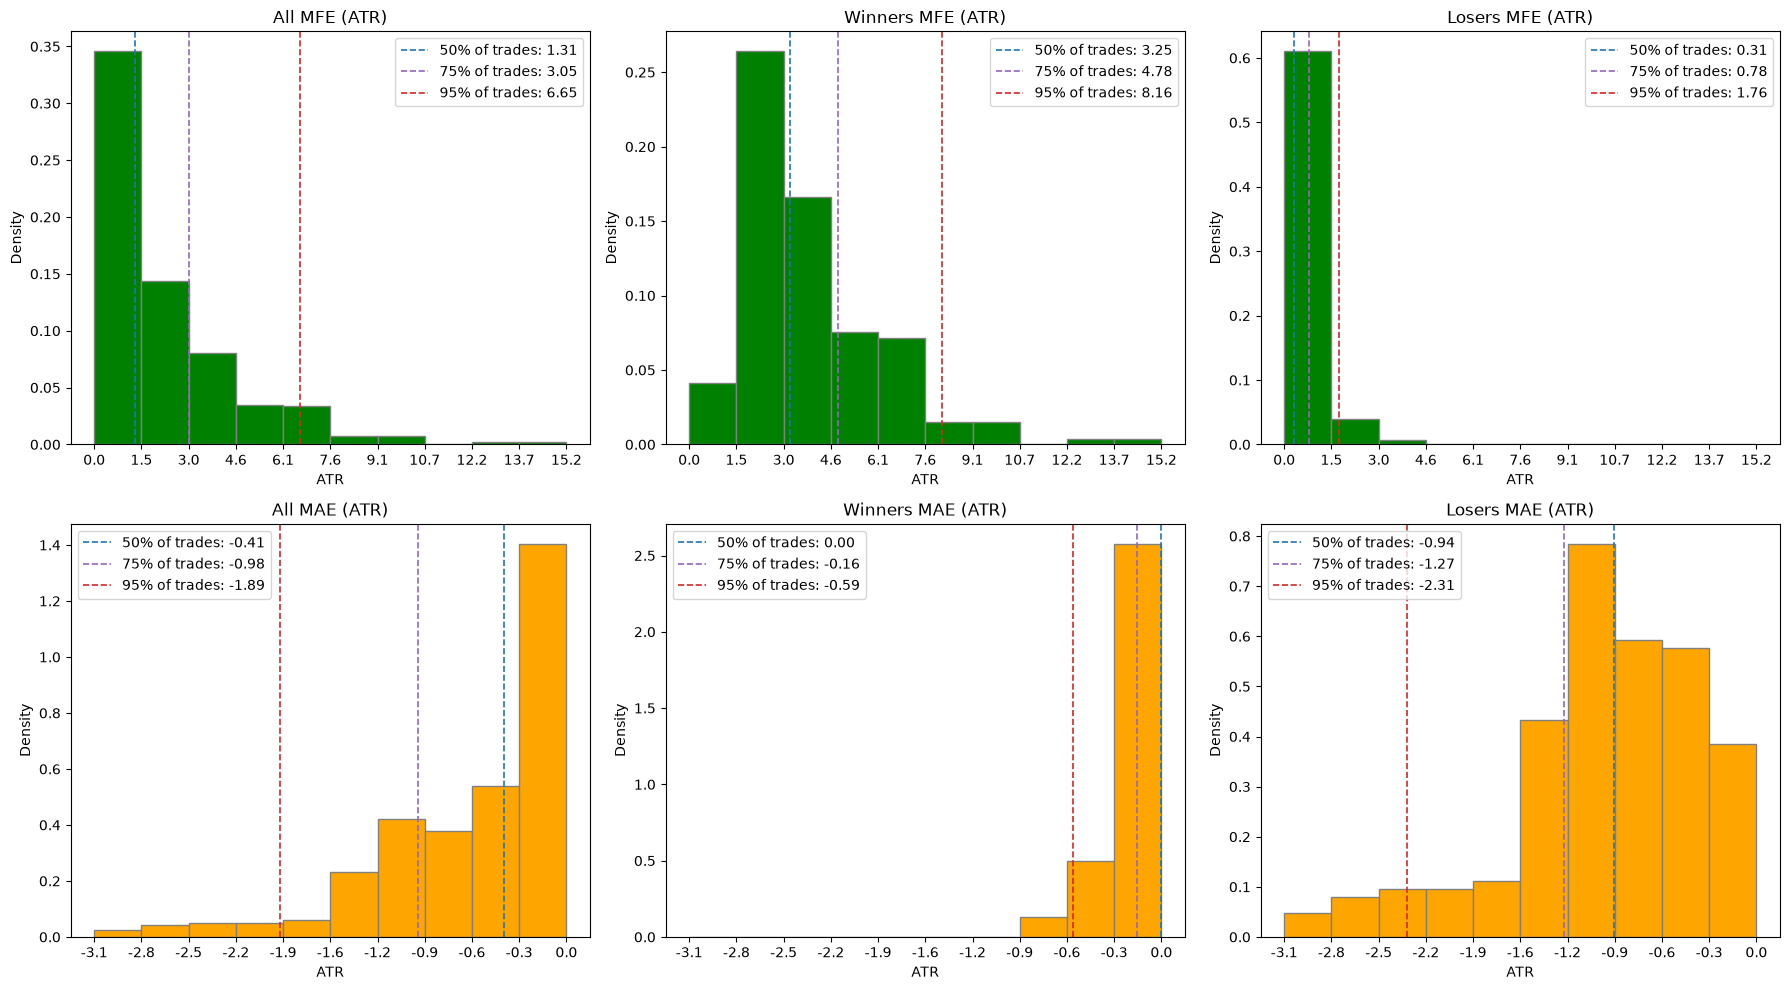

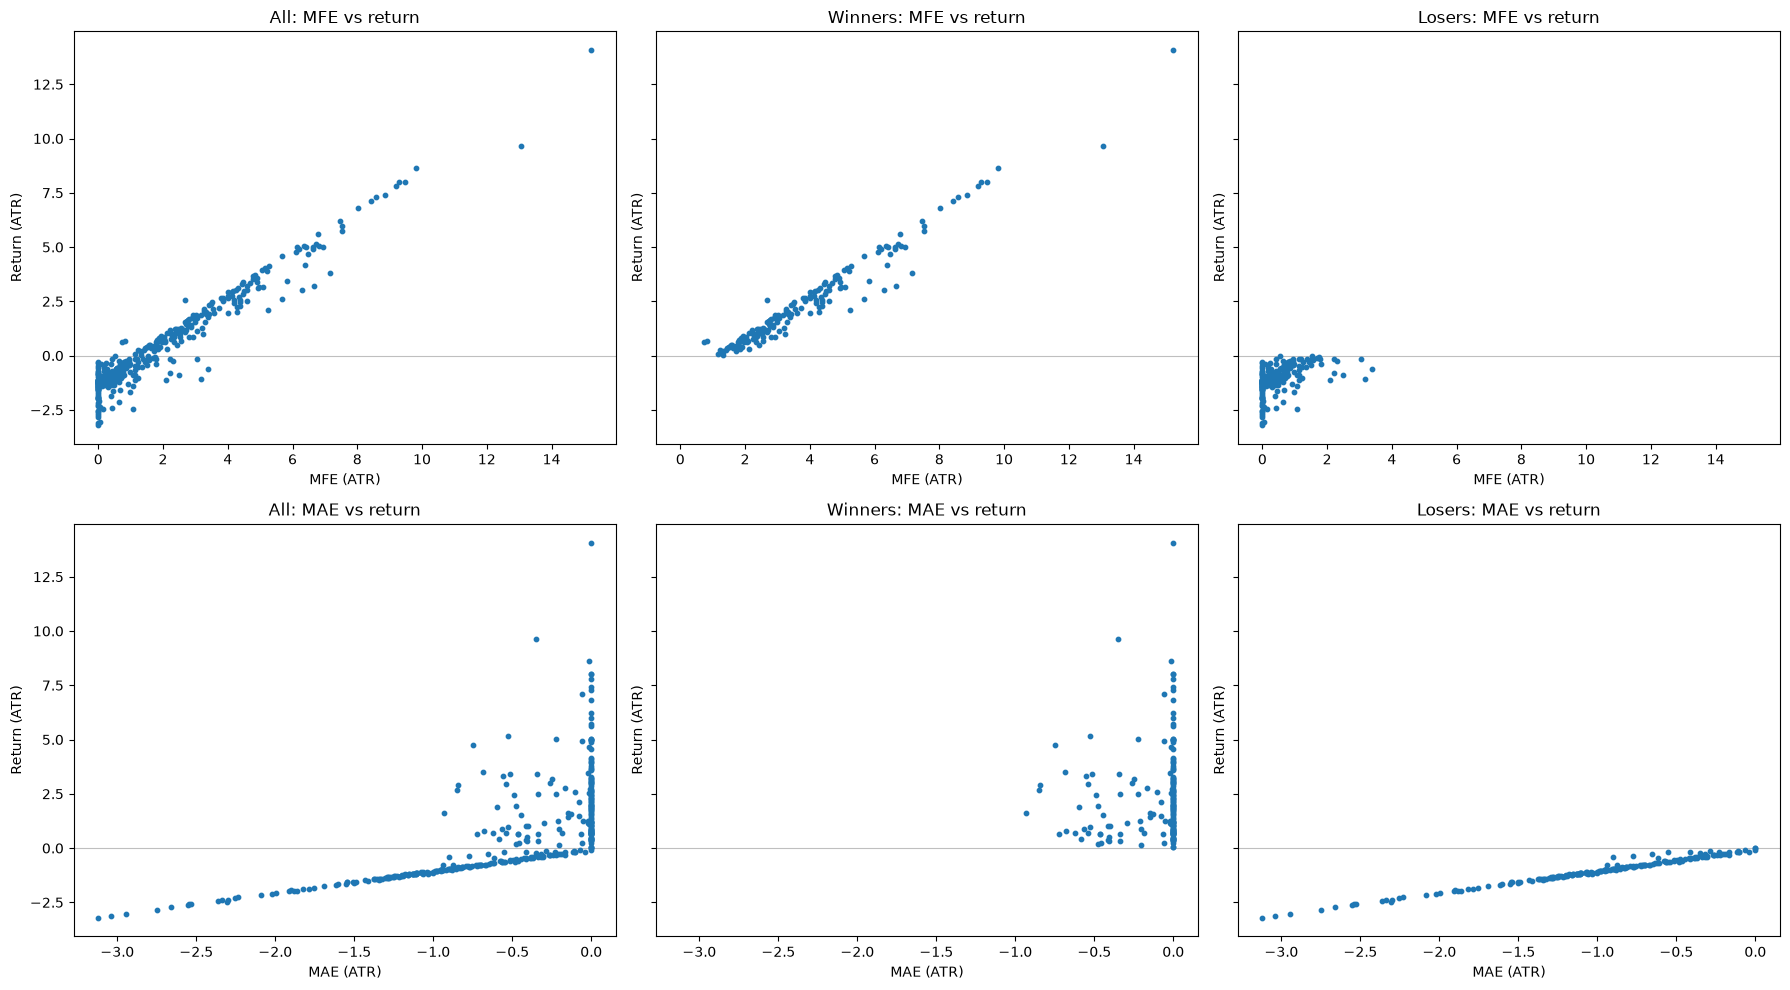

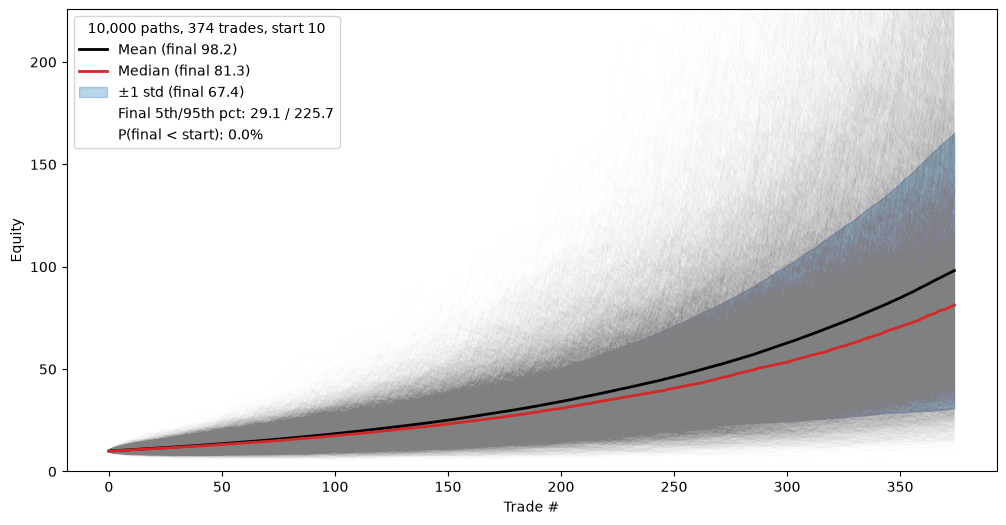

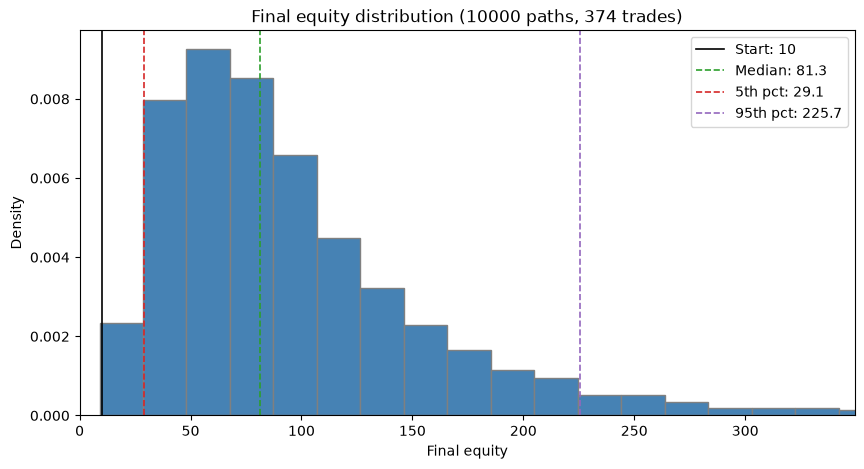

P(loss): 0.0%


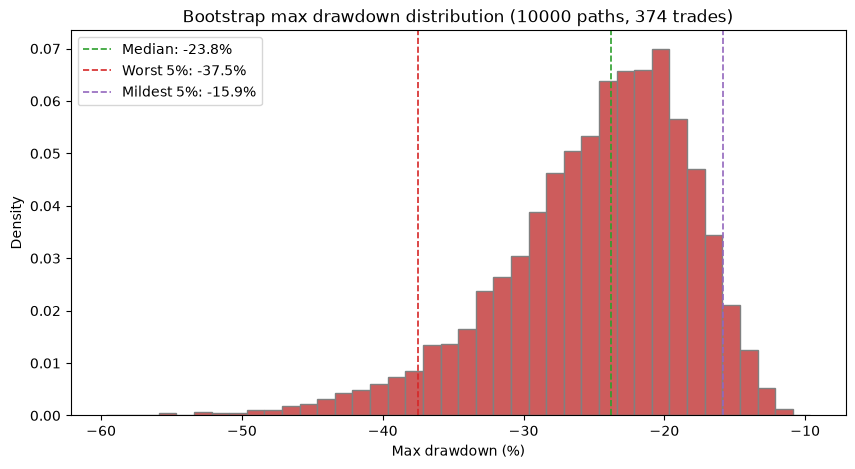

P(maxDD worse than -20%): 75.1%
MaxDD -26.5% on 2020-06-24 | Longest underwater 395d | Median episode 6d | Time underwater 91% | Currently 158d under


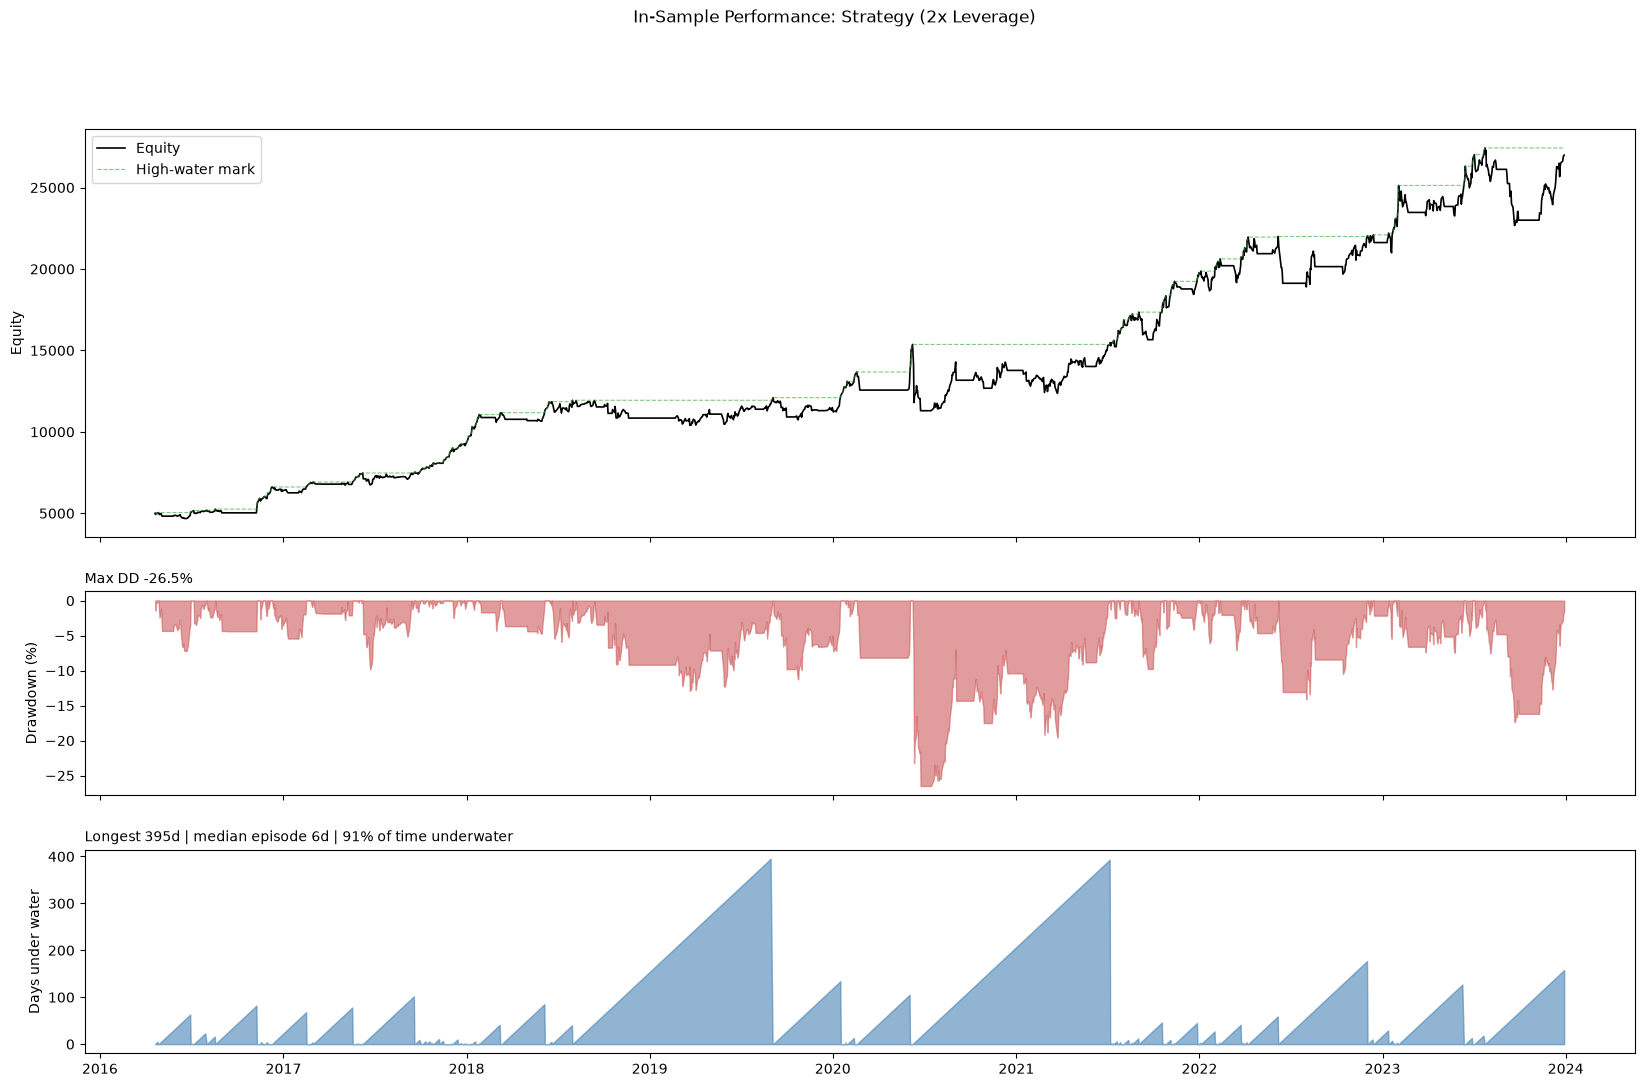

Total return (%)            439.73
CAGR (%)                     24.51
Ann. vol (%)                 19.41
Sharpe                        1.23
Sortino                       1.74
Max DD (%)                  -26.49
Calmar                        0.93
Max DD duration (d)         394.00
Longest underwater (d)      395.00
Time underwater (%)          91.18
Signals                     374.00
Trades filled               311.00
Skipped, no capacity (%)     16.84
Win rate (%)                 47.27
Profit factor                 1.85
Payoff (avg W / avg L)        2.06
Expectancy (R)                0.30
Days in market (%)           66.15
Peak leverage (x)             2.00
rho = 0.3422180053690231
S_i = 0.7645066551628856
rho*S_p = 0.4204901938943647
W_i = 0.27238028353879873
                          Strategy     SPY     Mix
Ann. vol (%)                 19.41   18.44   16.53
CAGR (%)                     24.51   13.18   21.89
Calmar                        0.93    0.39    1.02
Days in market (%)        

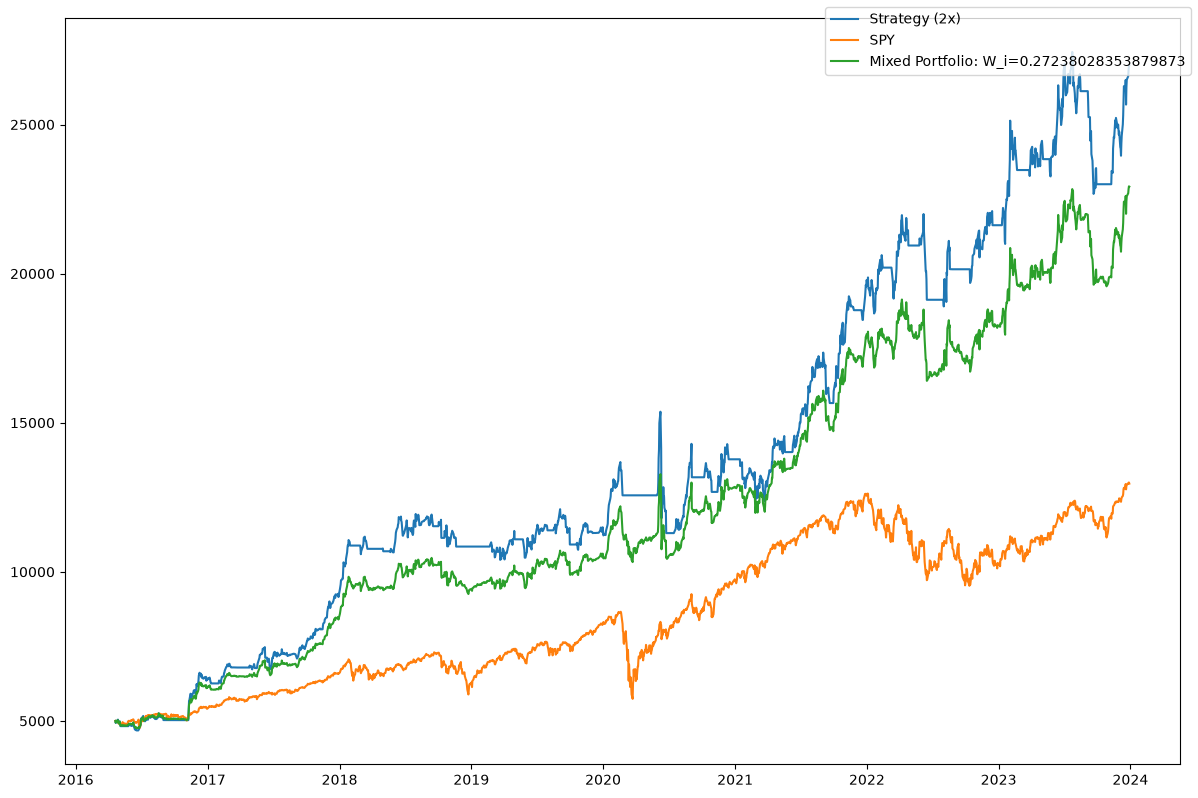

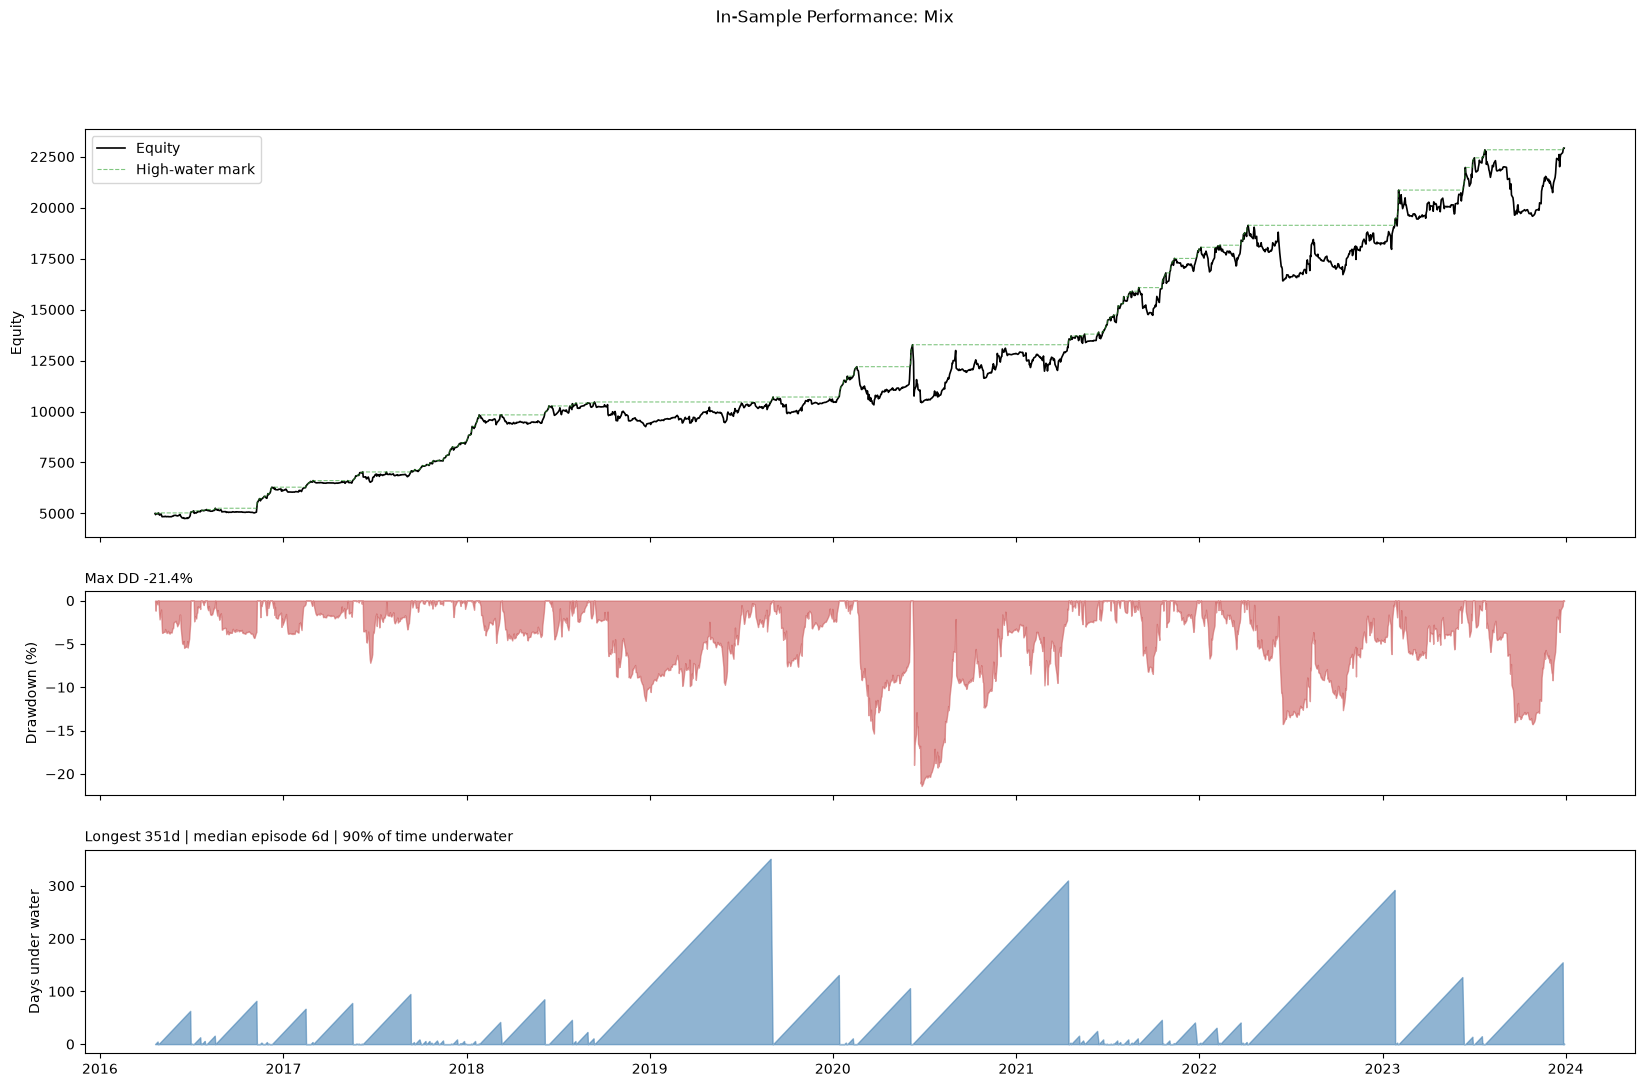

In [46]:
df = train_data
trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = f'In-Sample Performance: Strategy ({MAX_LEVERAGE}x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

train_W_i = bf.SPY_combo(daily,t,is_train=True,title='In-Sample Performance: Mix')

# HEATMAP SPIKE (TEST)

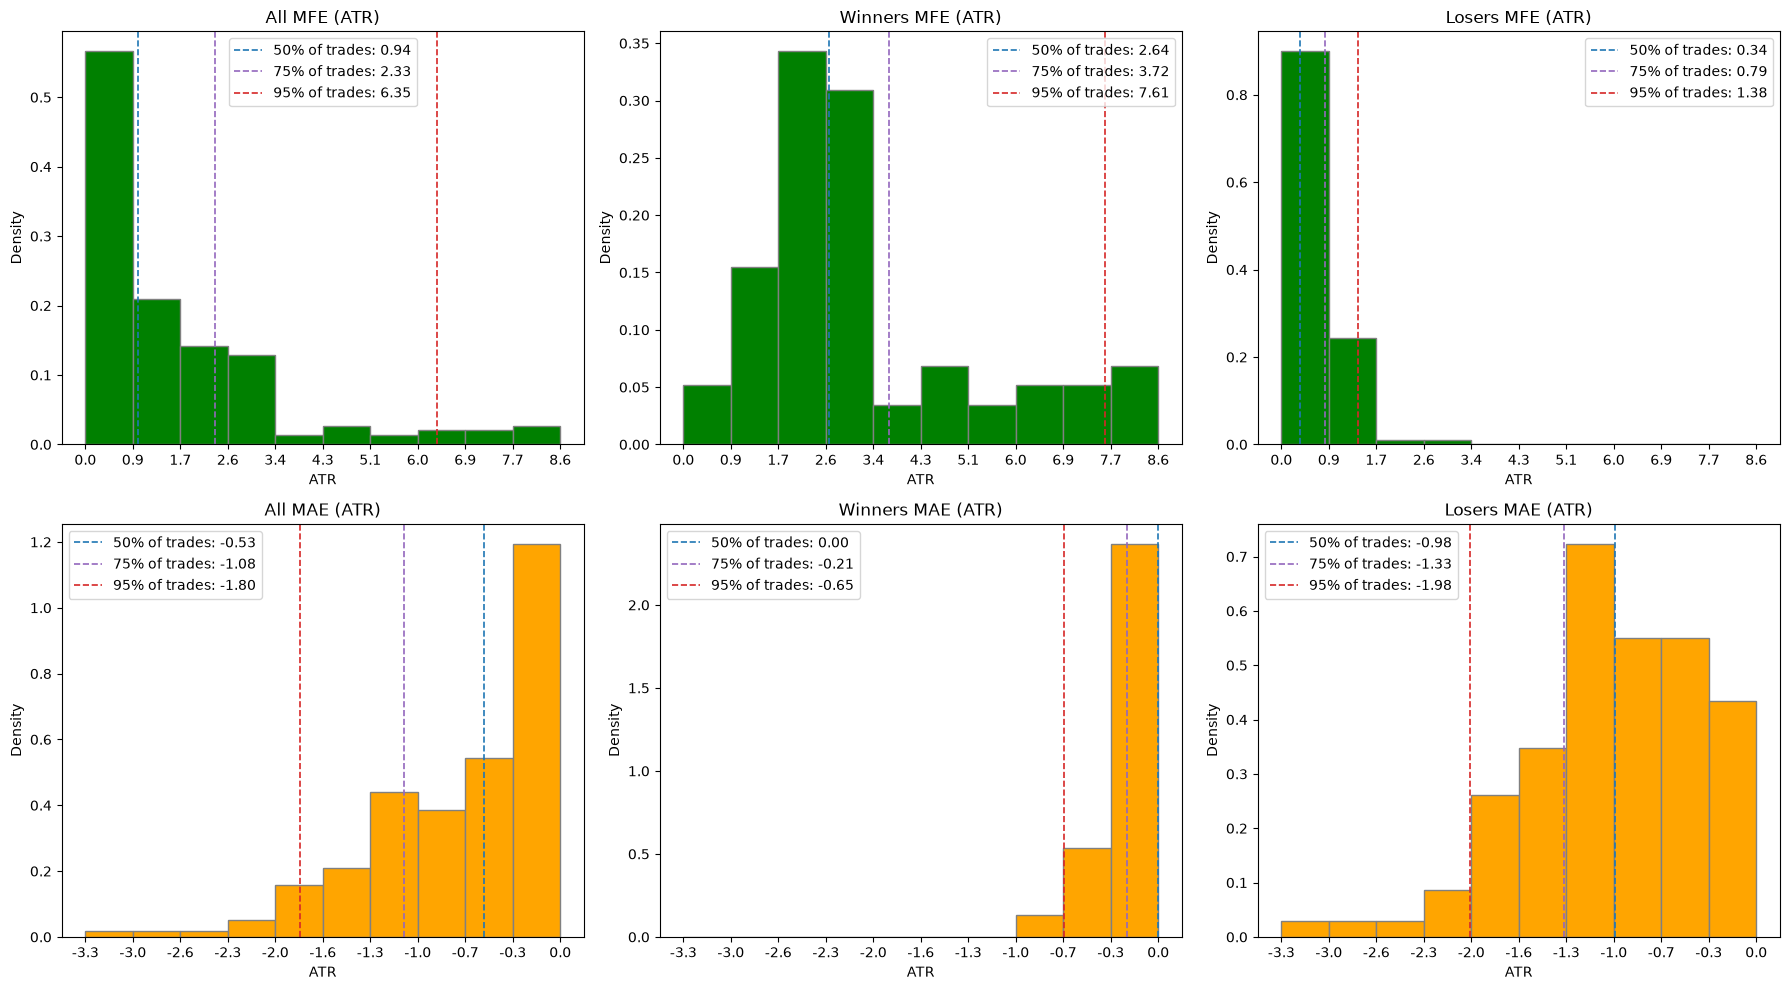

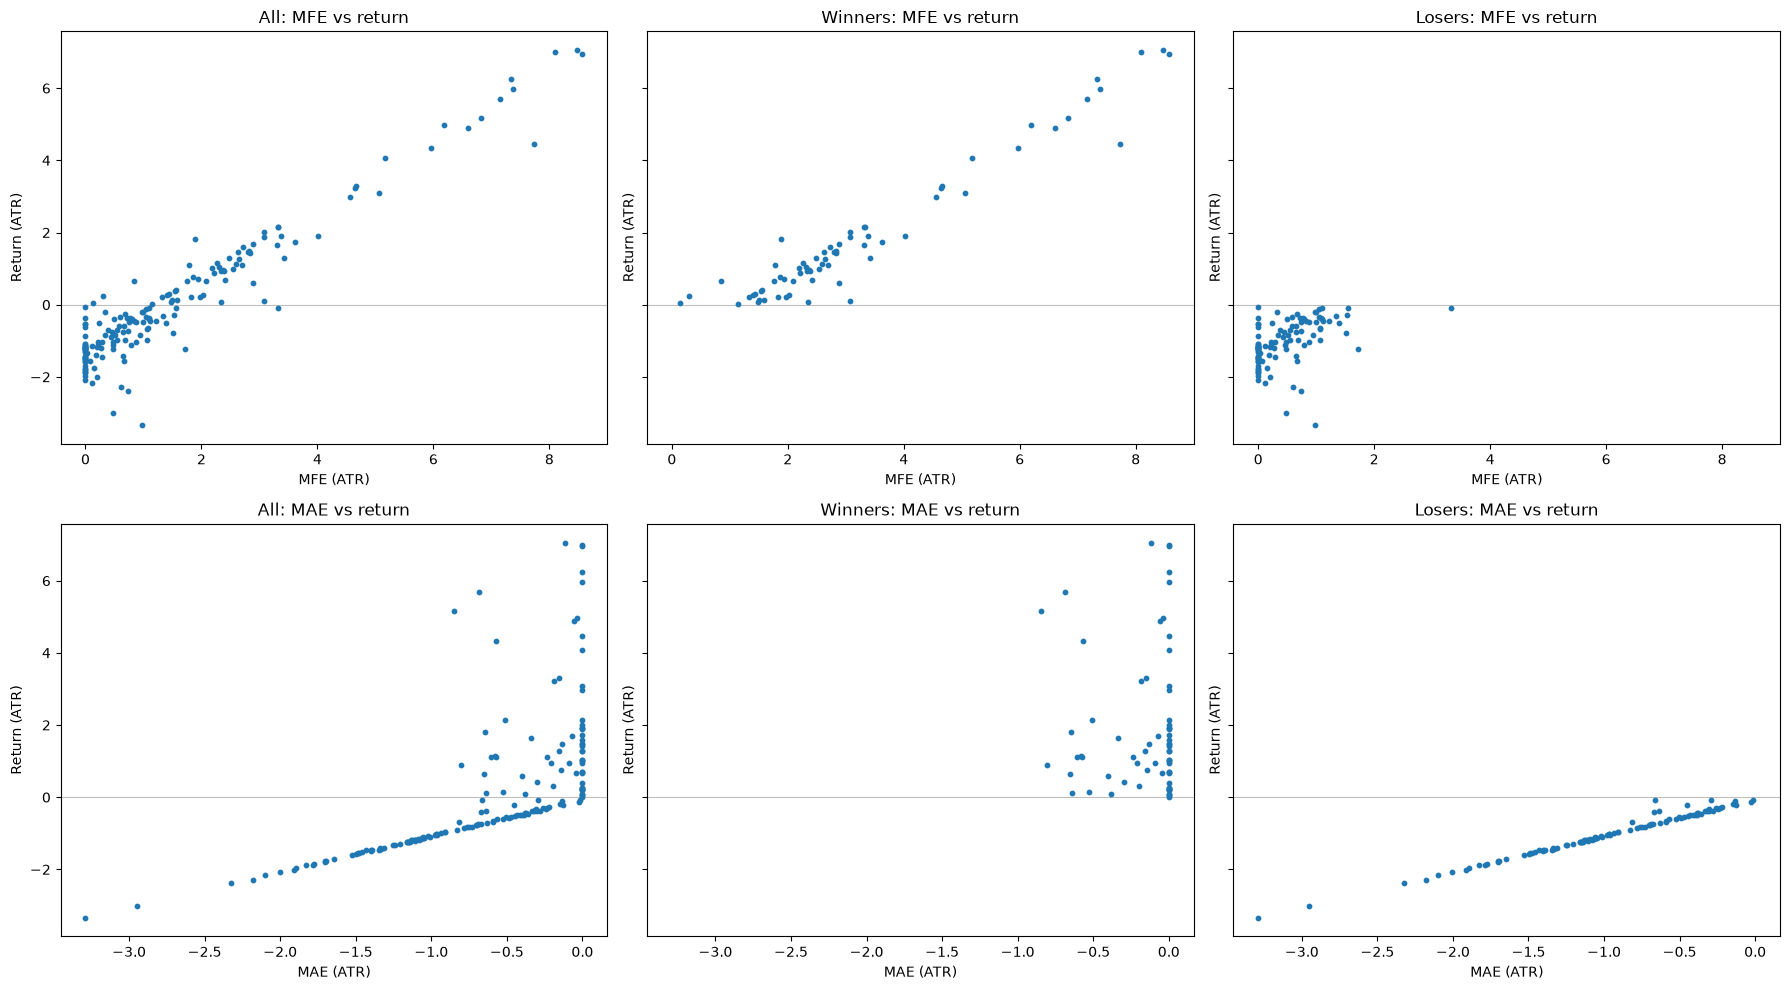

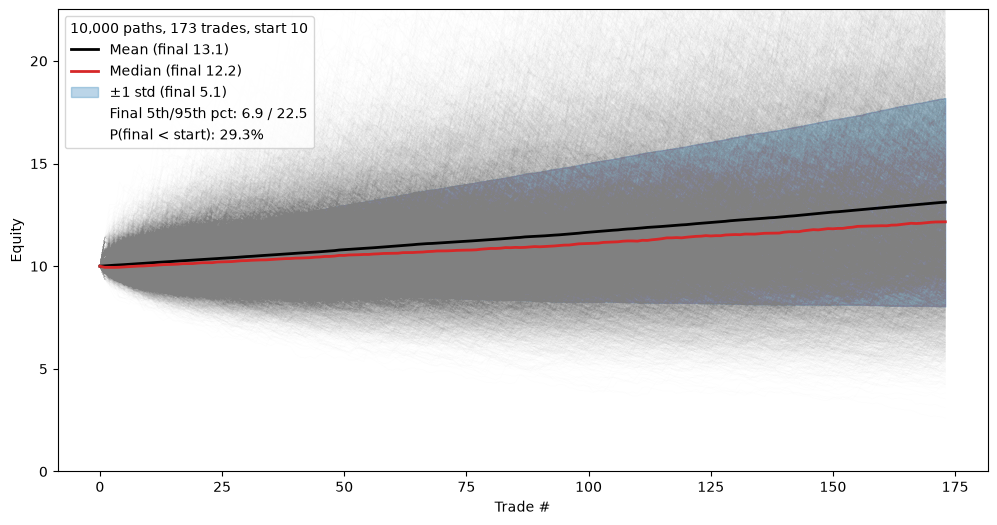

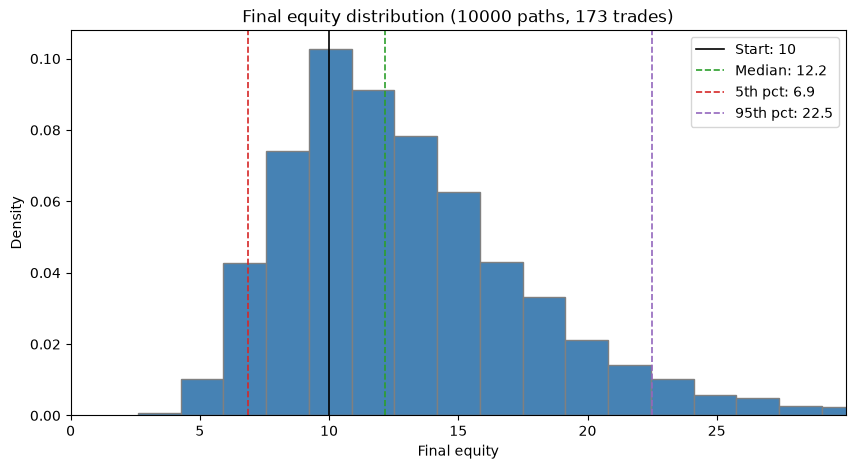

P(loss): 29.3%


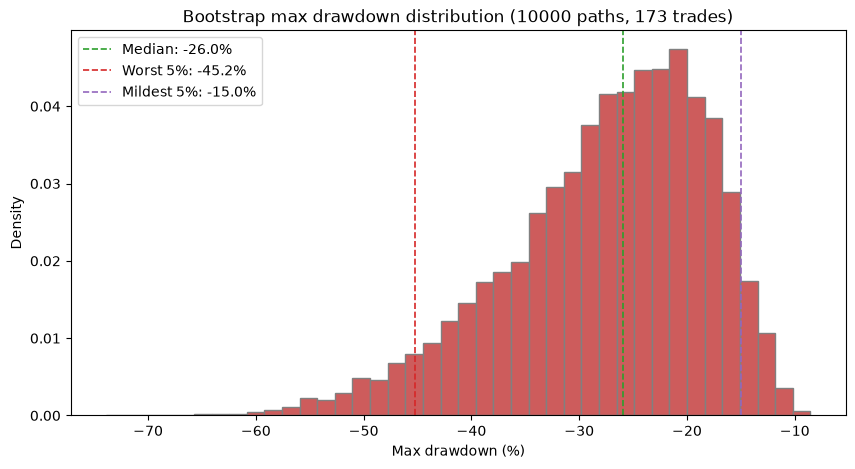

P(maxDD worse than -20%): 76.9%
MaxDD -19.3% on 2026-01-20 | Longest underwater 296d | Median episode 10d | Time underwater 93% | Currently 4d under


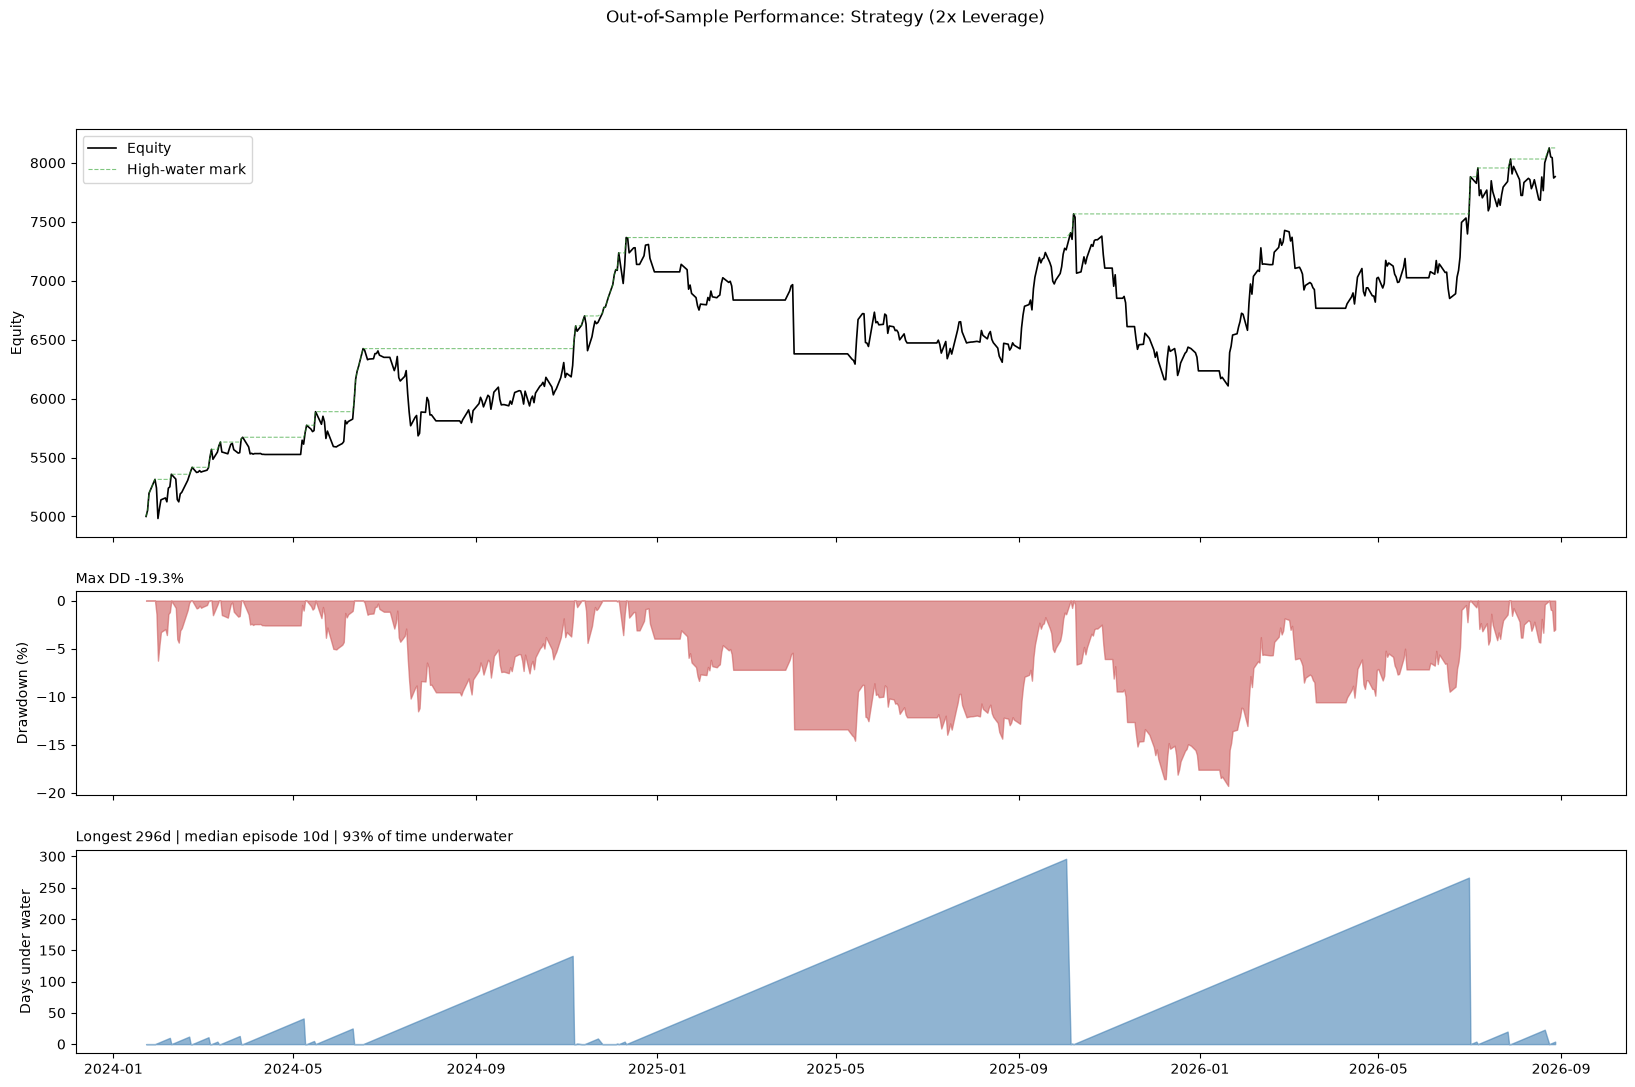

Total return (%)             57.66
CAGR (%)                     19.17
Ann. vol (%)                 19.92
Sharpe                        0.98
Sortino                       1.41
Max DD (%)                  -19.29
Calmar                        0.99
Max DD duration (d)         267.00
Longest underwater (d)      296.00
Time underwater (%)          93.42
Signals                     173.00
Trades filled               140.00
Skipped, no capacity (%)     19.08
Win rate (%)                 42.86
Profit factor                 1.67
Payoff (avg W / avg L)        2.23
Expectancy (R)                0.18
Days in market (%)           77.34
Peak leverage (x)             2.00
rho = 0.34175997591901136
S_i = 1.2810181627204613
rho*S_p = 0.33612489195726697
W_i = 0.6858284809369305
                          Strategy     SPY     Mix
Ann. vol (%)                 19.92   15.80   16.47
CAGR (%)                     19.17   20.84   20.13
Calmar                        0.99    1.11    1.39
Days in market (%)       

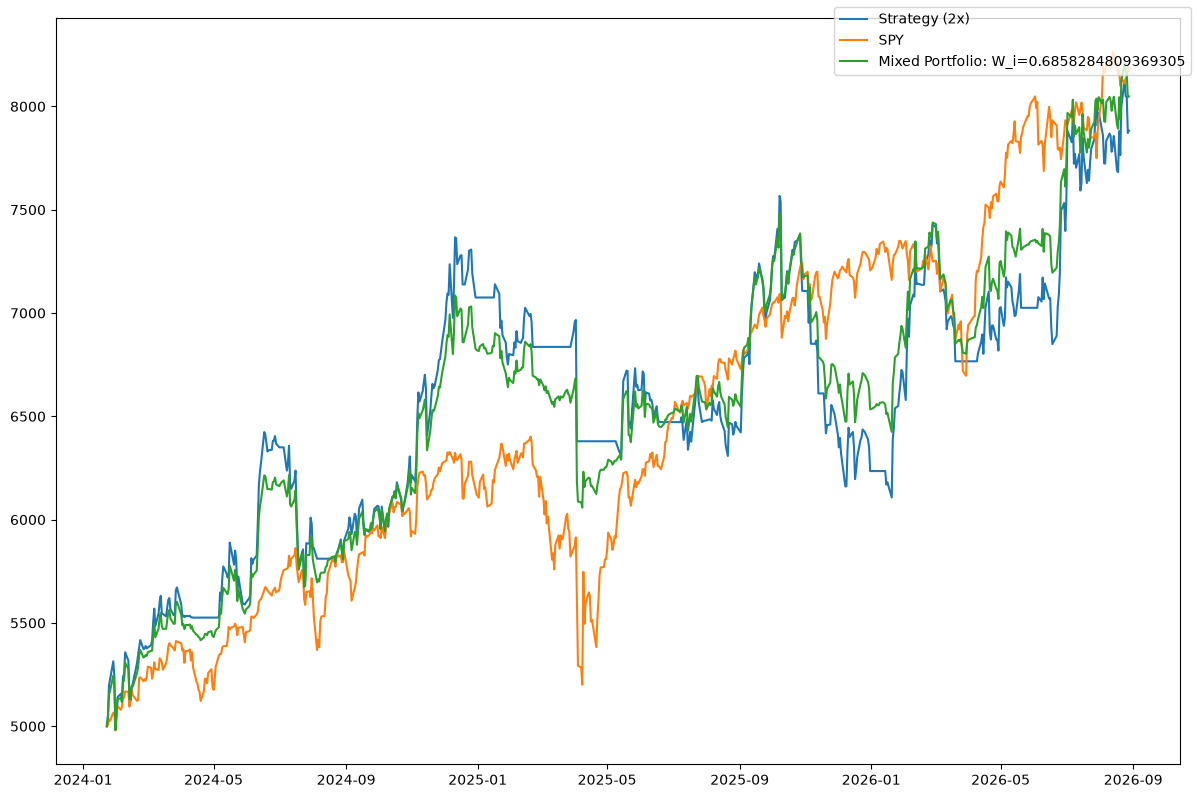

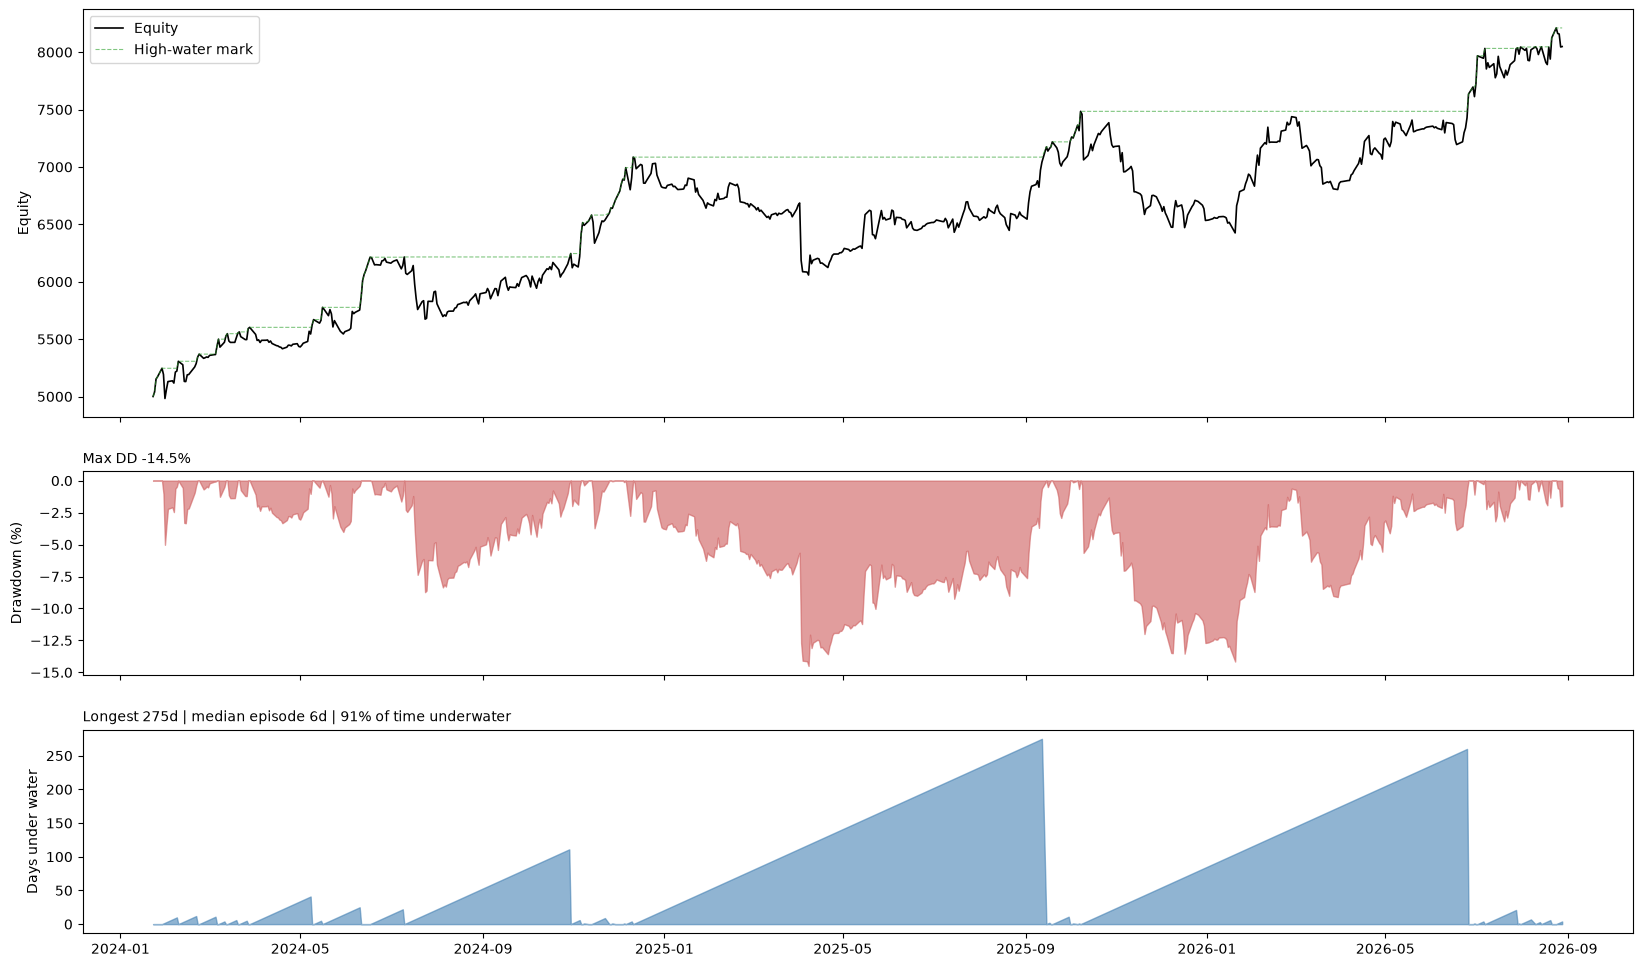

In [47]:
df = test_data
trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = f'Out-of-Sample Performance: Strategy ({MAX_LEVERAGE}x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

bf.SPY_combo(daily,t,train_weight=train_W_i,is_train=False)

# HEATMAP SPIKE (FULL)

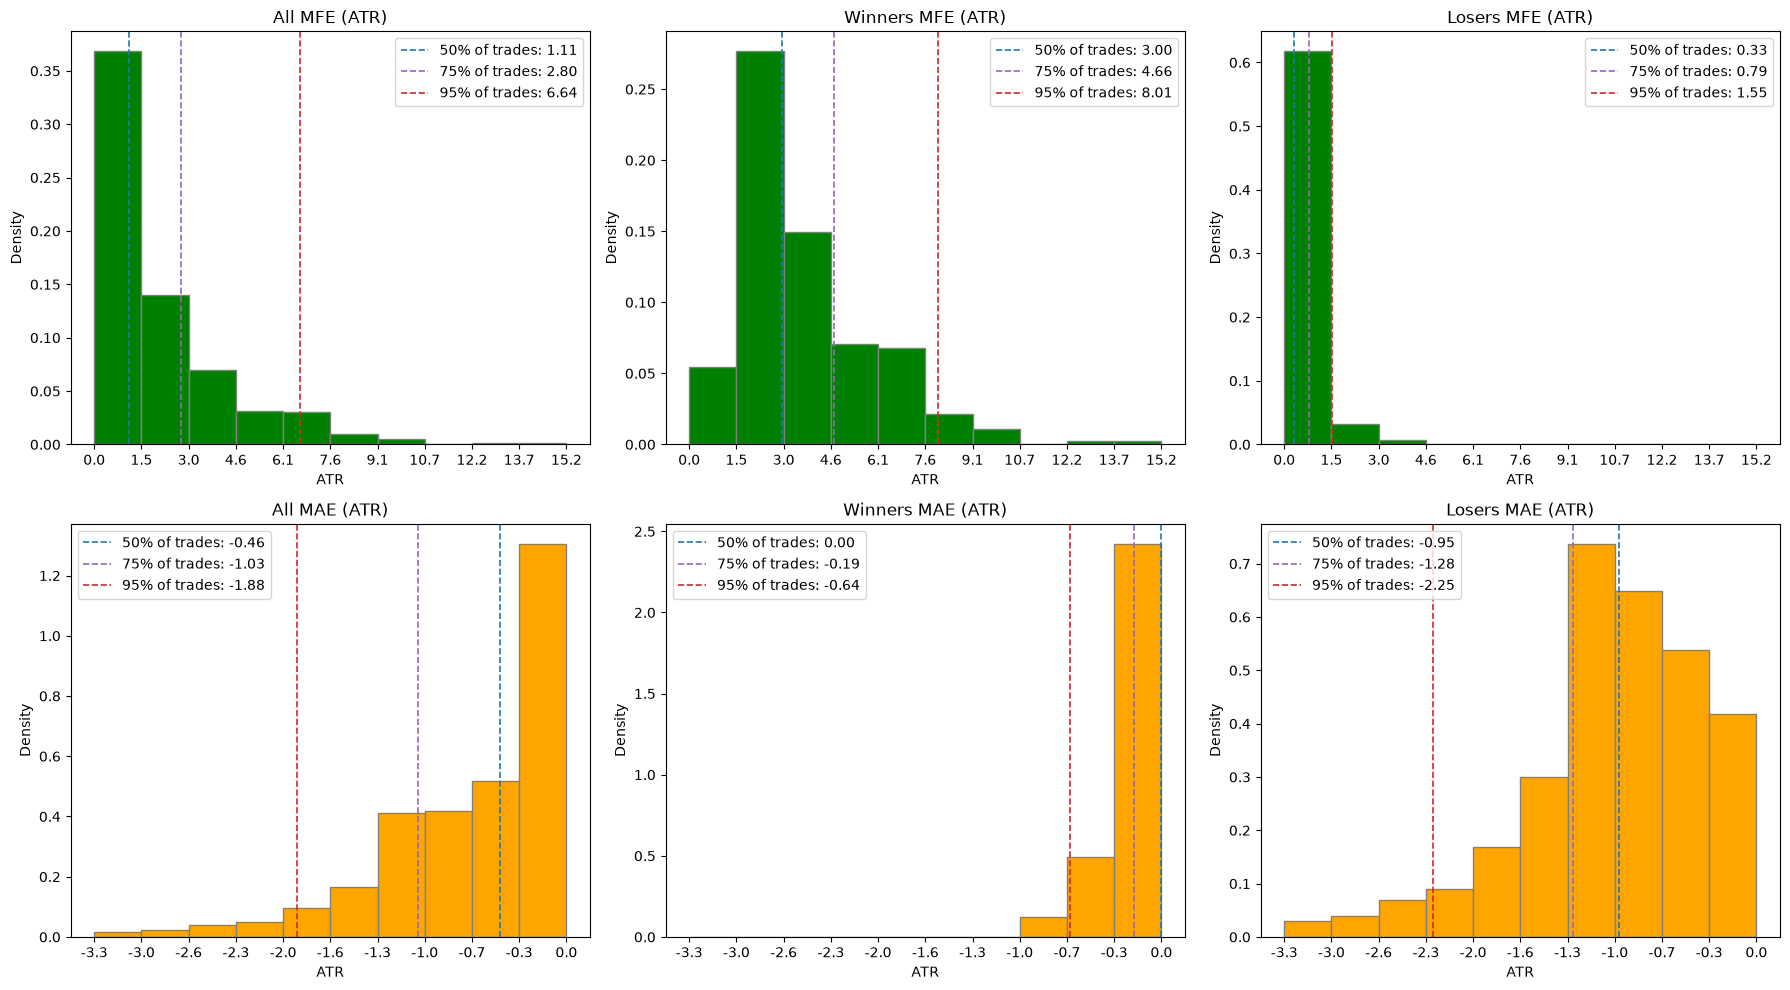

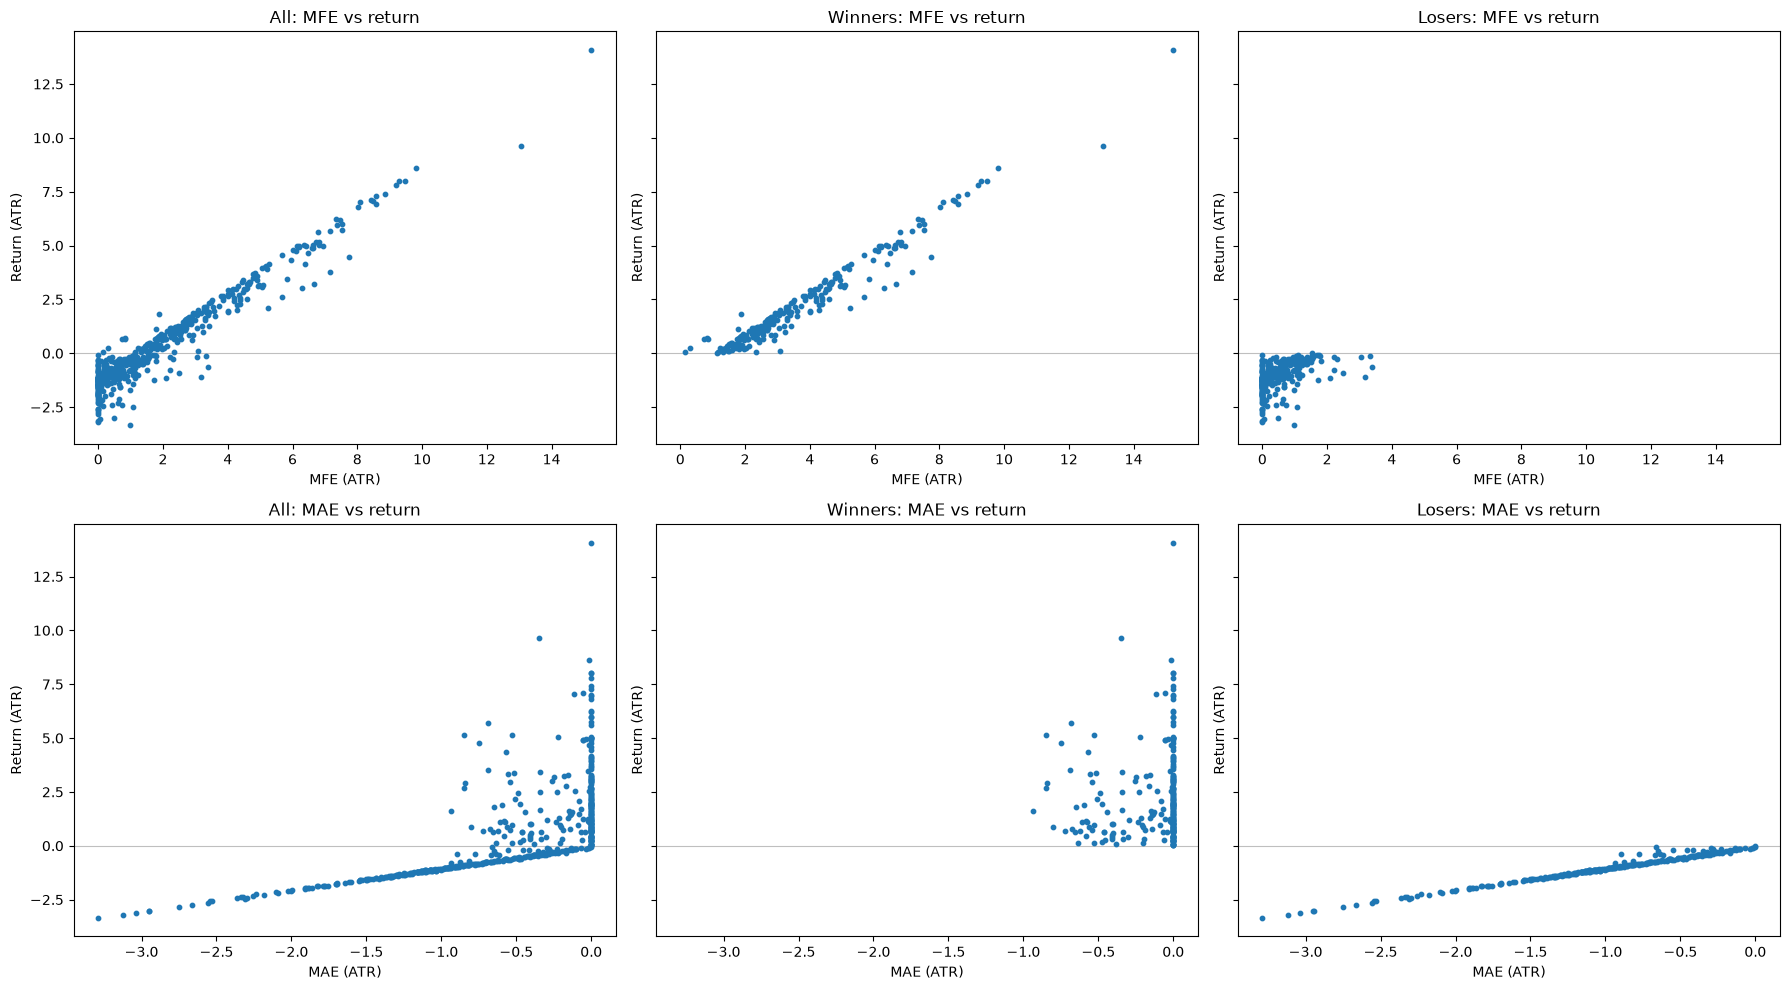

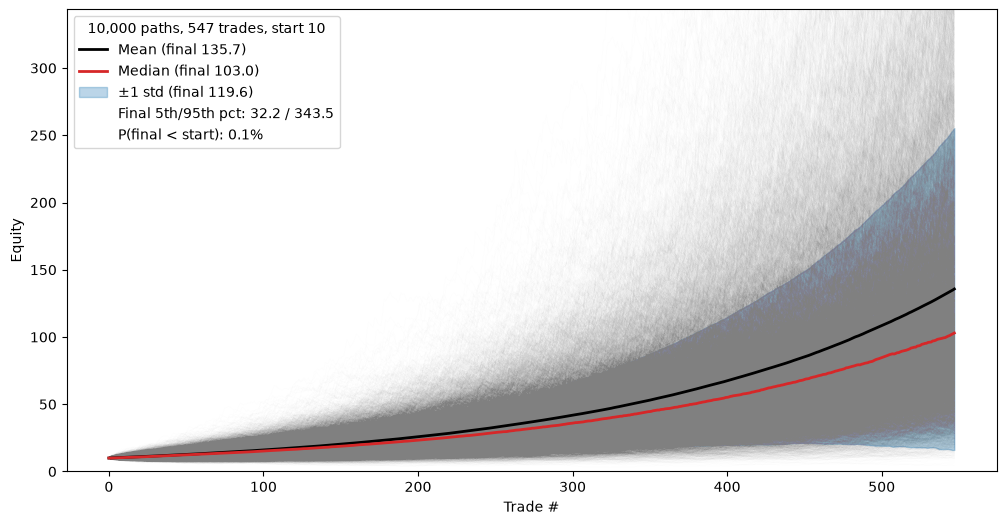

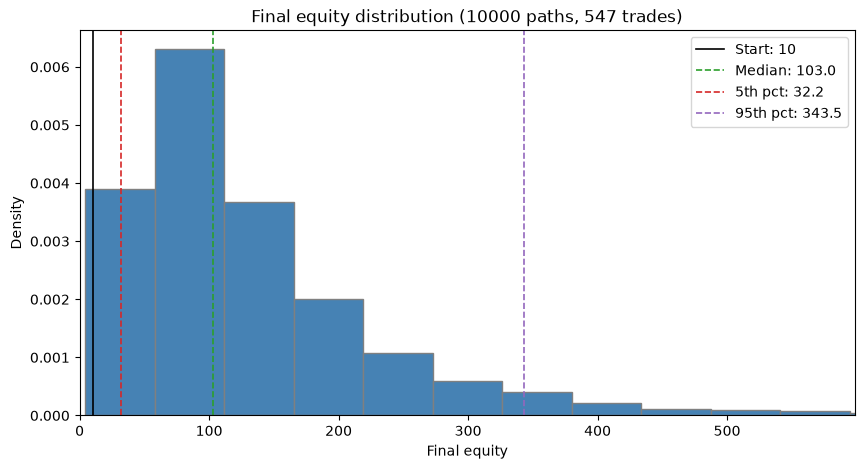

P(loss): 0.1%


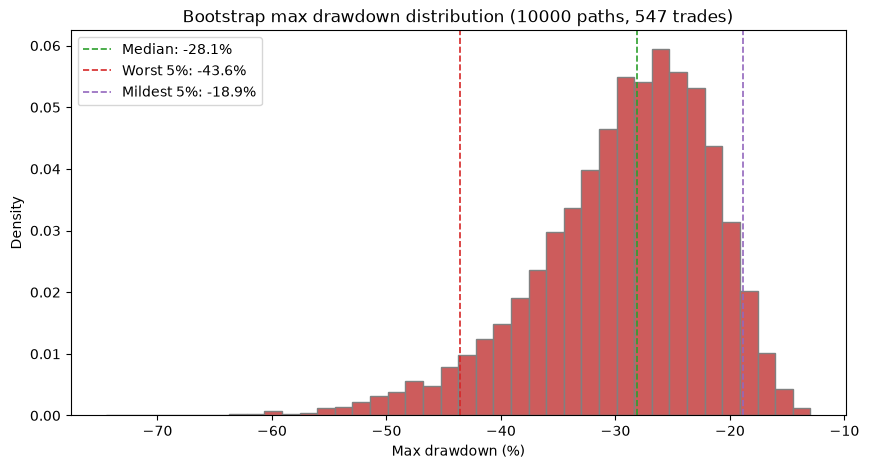

P(maxDD worse than -20%): 92.0%
MaxDD -26.5% on 2020-06-24 | Longest underwater 395d | Median episode 6d | Time underwater 92% | Currently 4d under


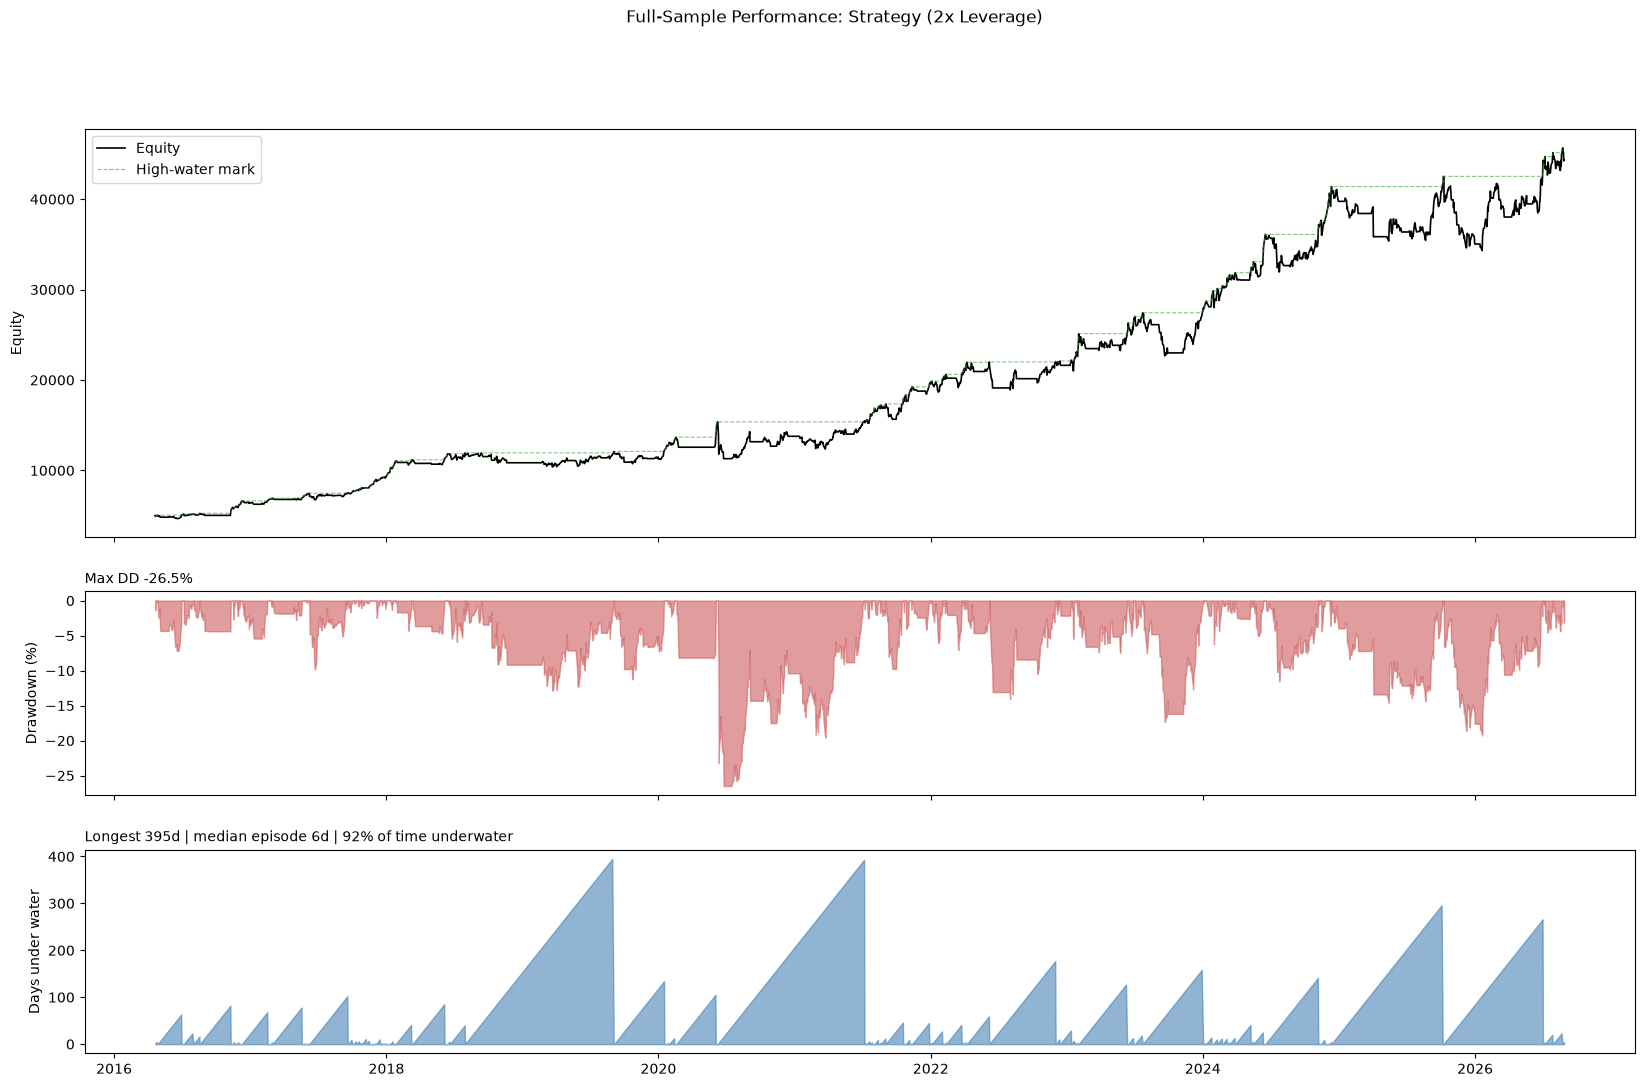

Total return (%)            786.00
CAGR (%)                     23.45
Ann. vol (%)                 19.52
Sharpe                        1.18
Sortino                       1.68
Max DD (%)                  -26.49
Calmar                        0.89
Max DD duration (d)         394.00
Longest underwater (d)      395.00
Time underwater (%)          91.71
Signals                     547.00
Trades filled               450.00
Skipped, no capacity (%)     17.73
Win rate (%)                 45.78
Profit factor                 1.78
Payoff (avg W / avg L)        2.11
Expectancy (R)                0.27
Days in market (%)           69.02
Peak leverage (x)             2.00
rho = 0.3403578448191054
S_i = 0.8860207127466606
rho*S_p = 0.4018180131962555
W_i = 0.37687060917329757
                          Strategy     SPY     Mix
Ann. vol (%)                 19.52   17.78   16.49
CAGR (%)                     23.45   15.18   21.70
Calmar                        0.89    0.45    1.01
Days in market (%)        

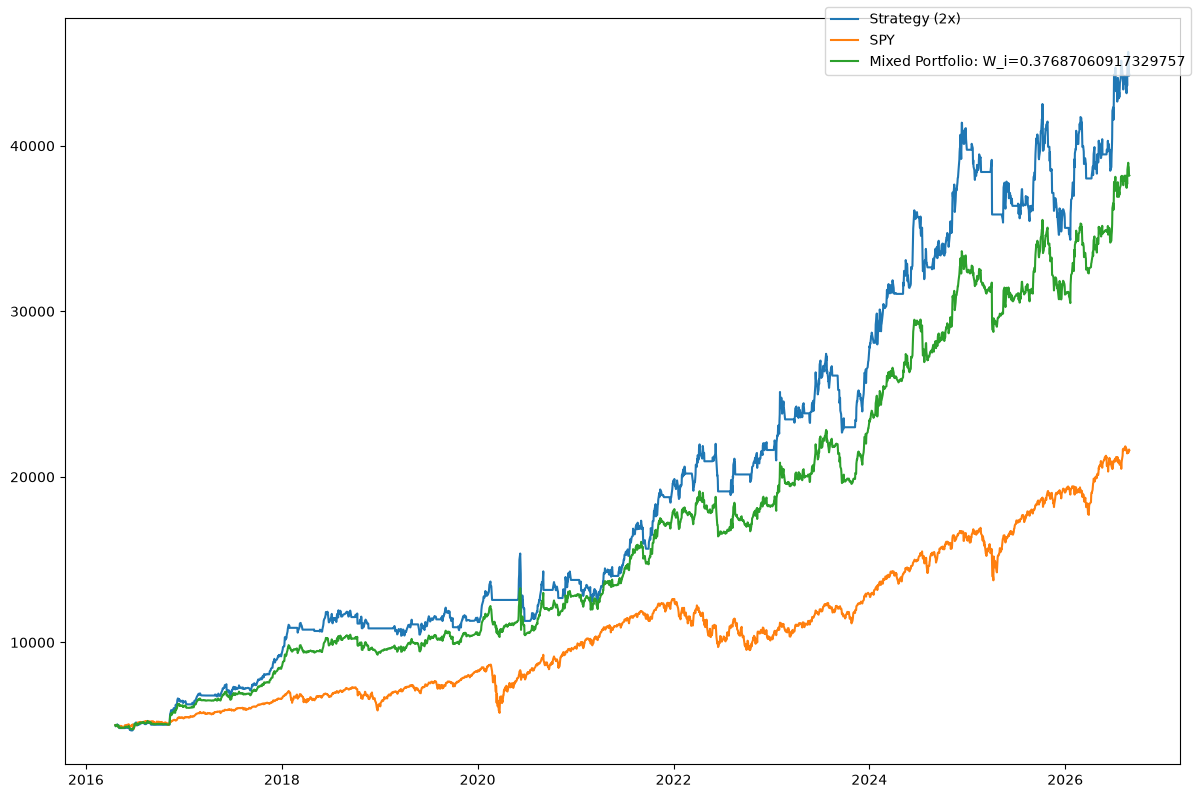

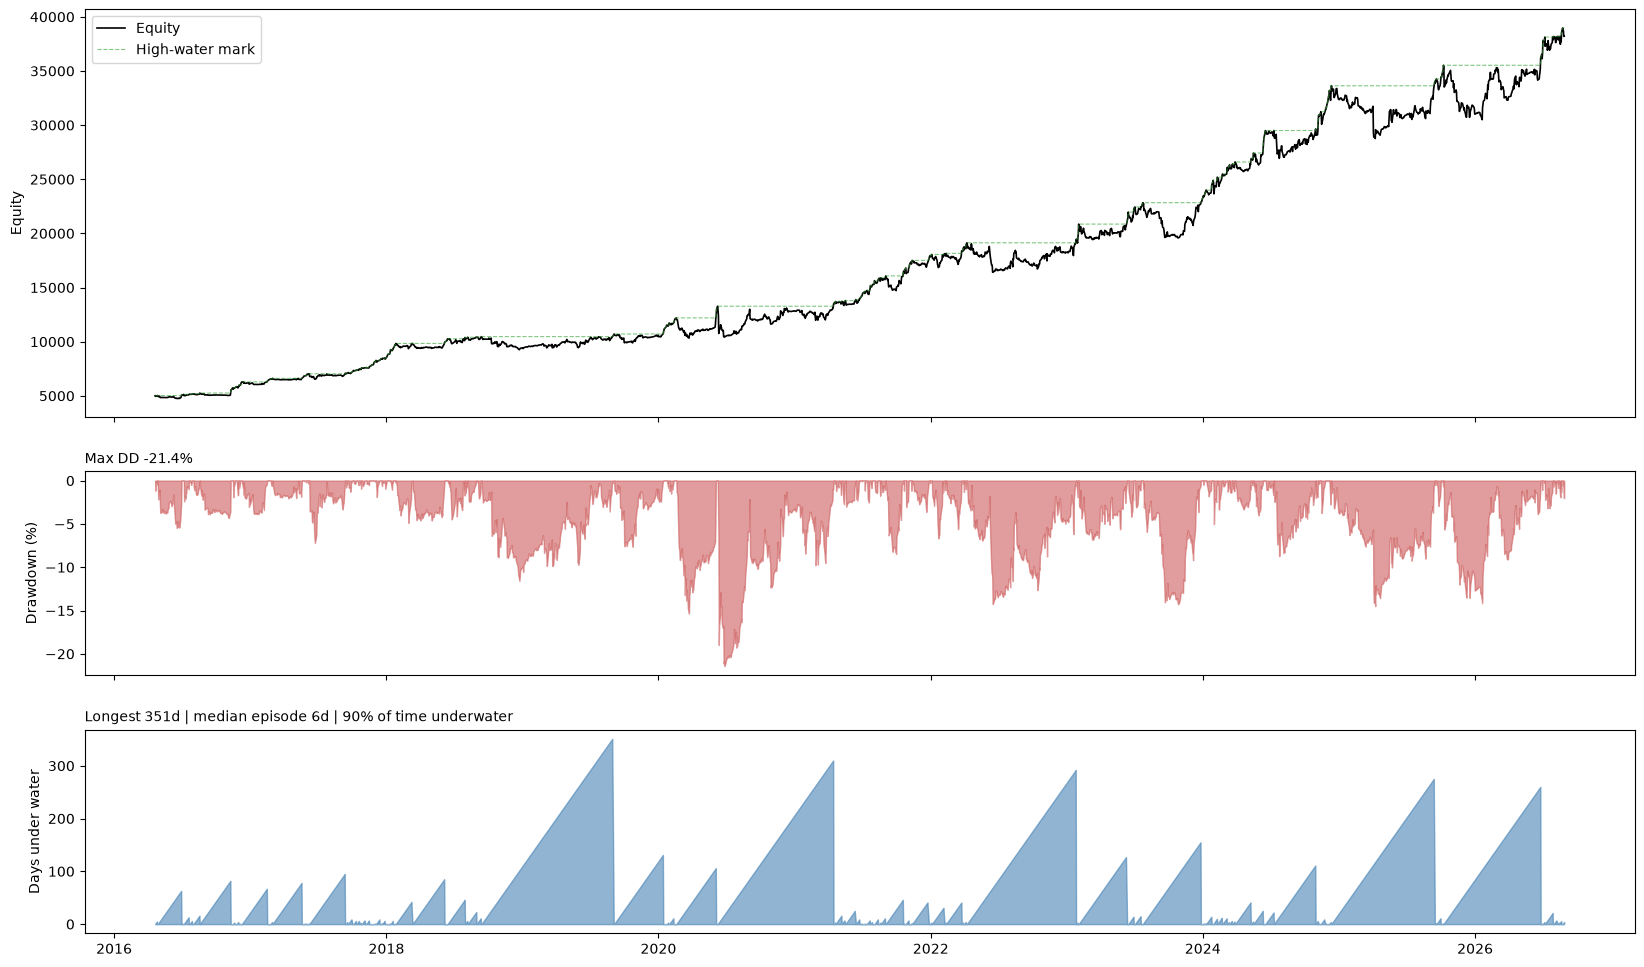

In [48]:
df = all_data
trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = f'Full-Sample Performance: Strategy ({MAX_LEVERAGE}x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

bf.SPY_combo(daily,t,train_weight=train_W_i,is_train=False)

# NO HEATMAP SPIKE (TRAIN)

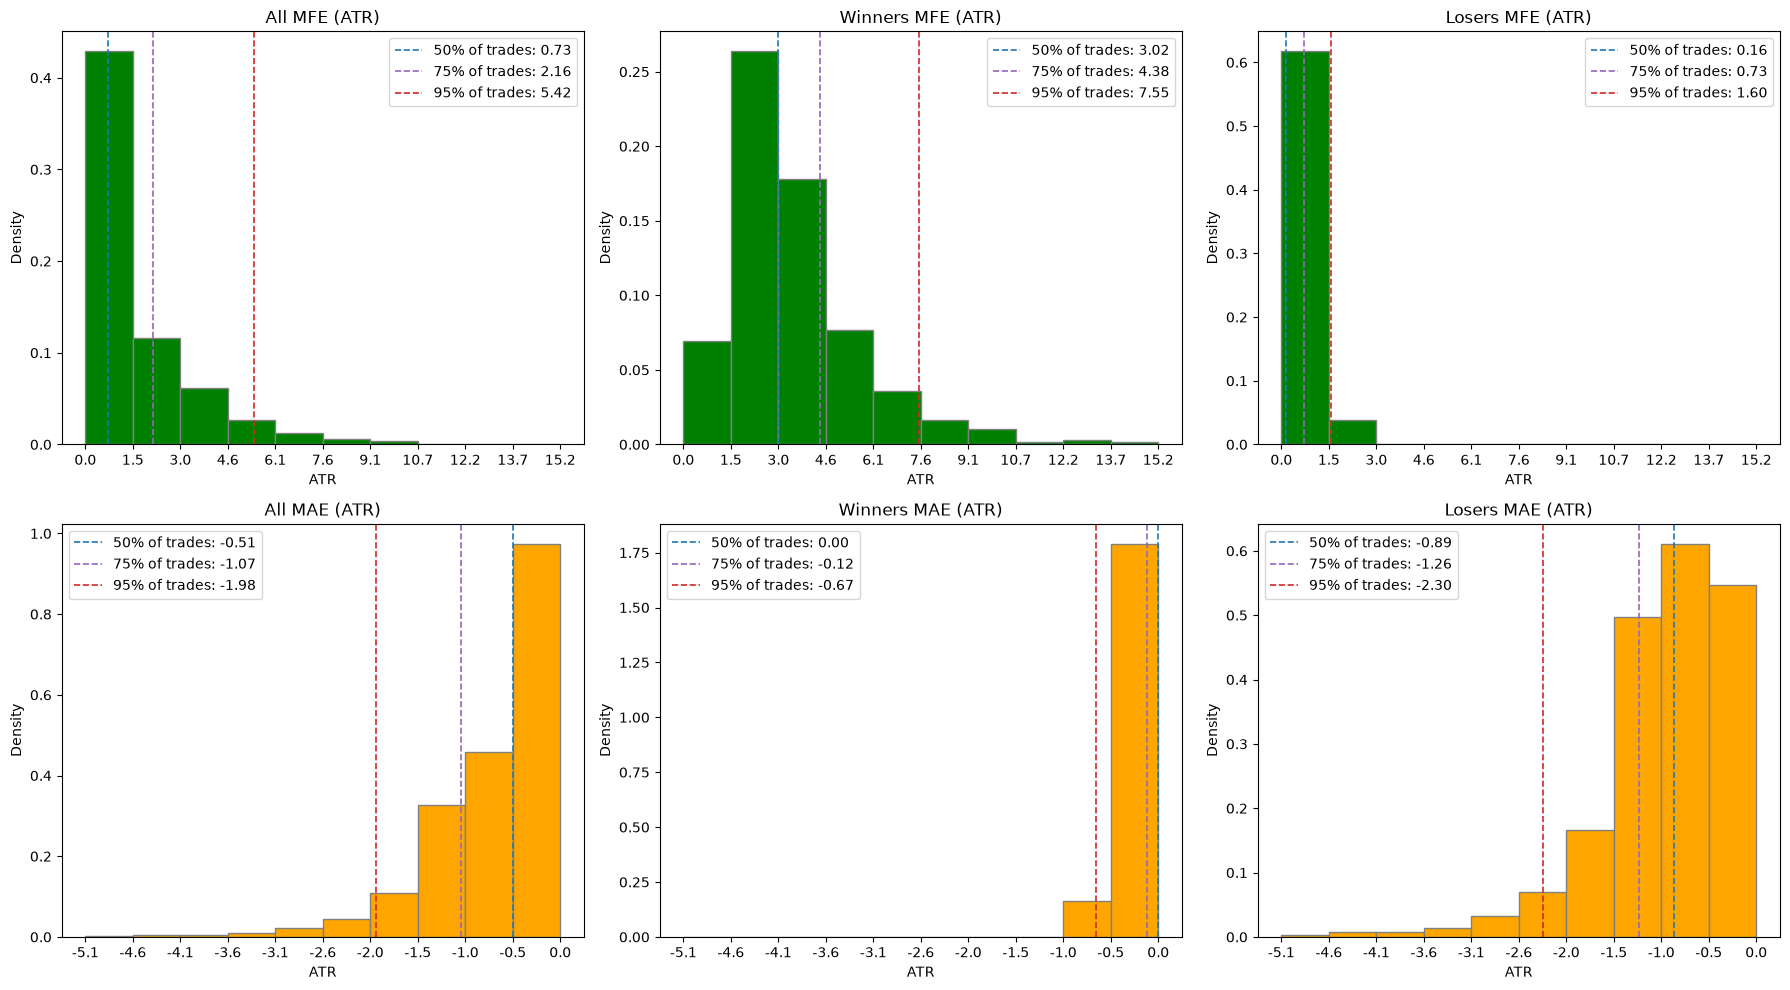

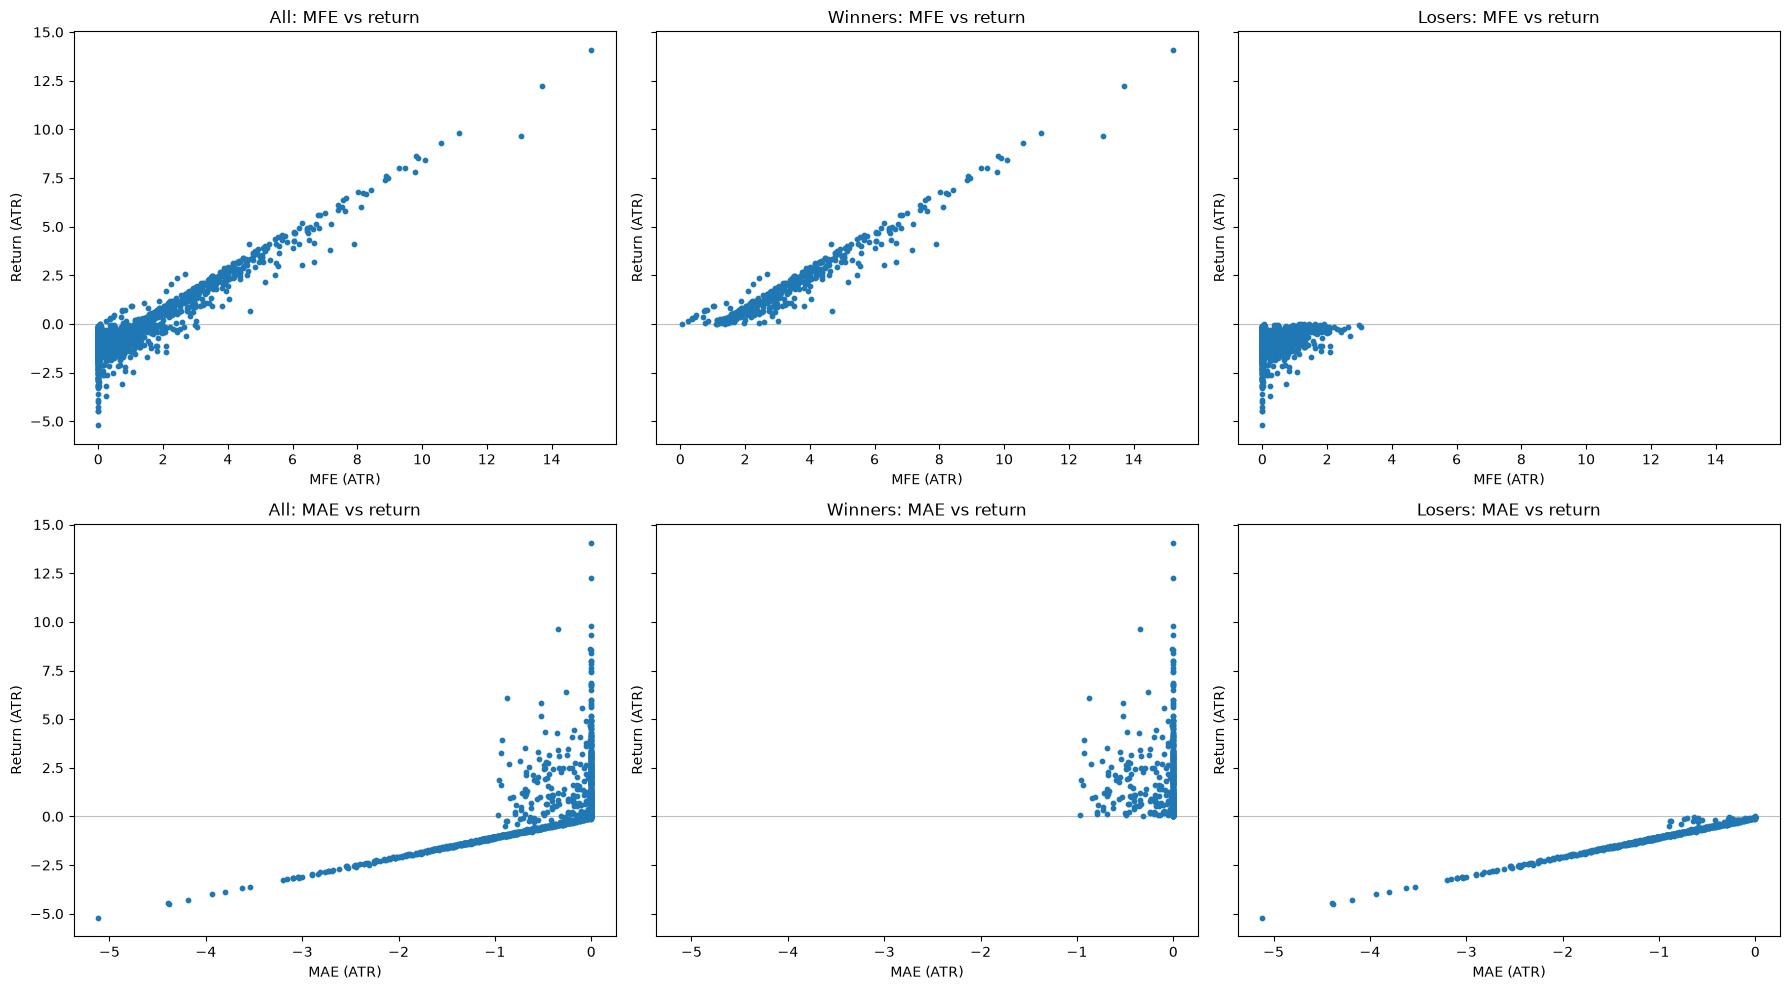

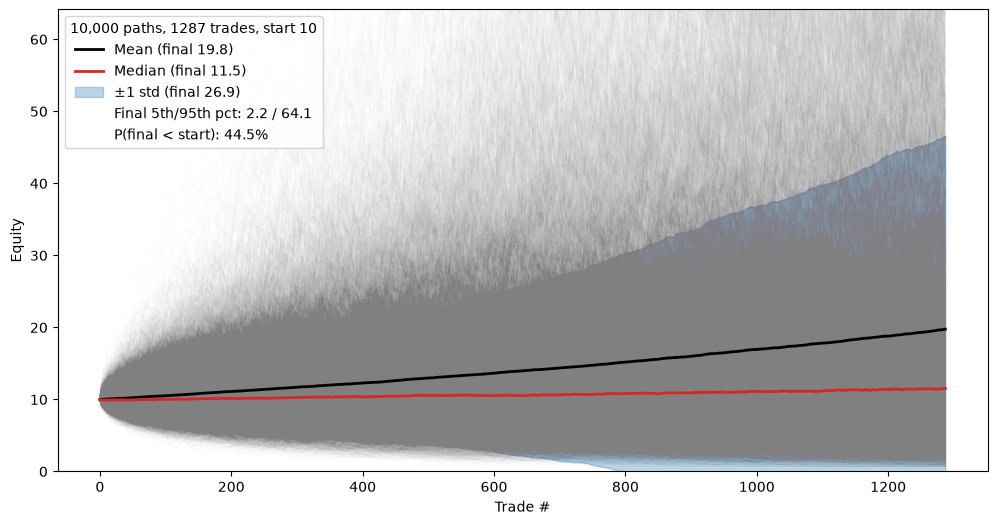

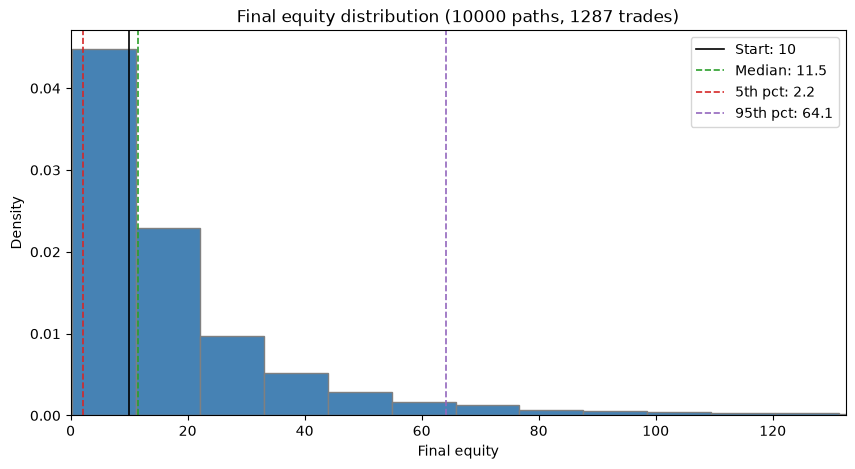

P(loss): 44.5%


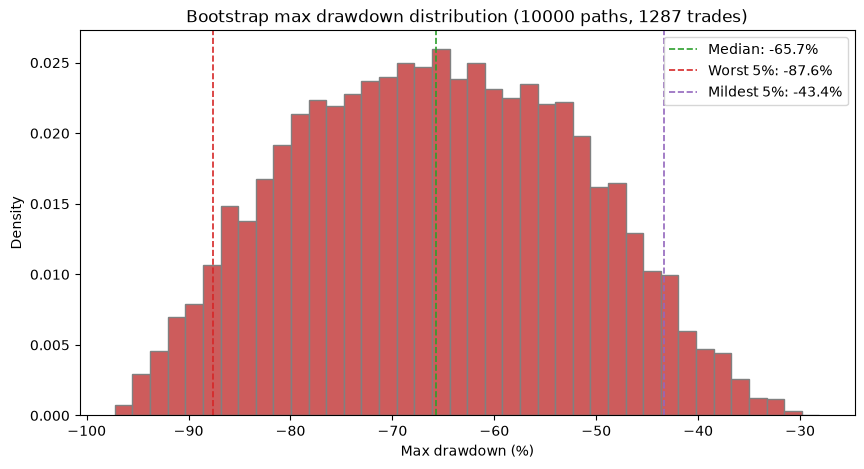

P(maxDD worse than -20%): 100.0%
MaxDD -60.3% on 2020-06-26 | Longest underwater 2163d | Median episode 3d | Time underwater 97% | Currently 2163d under


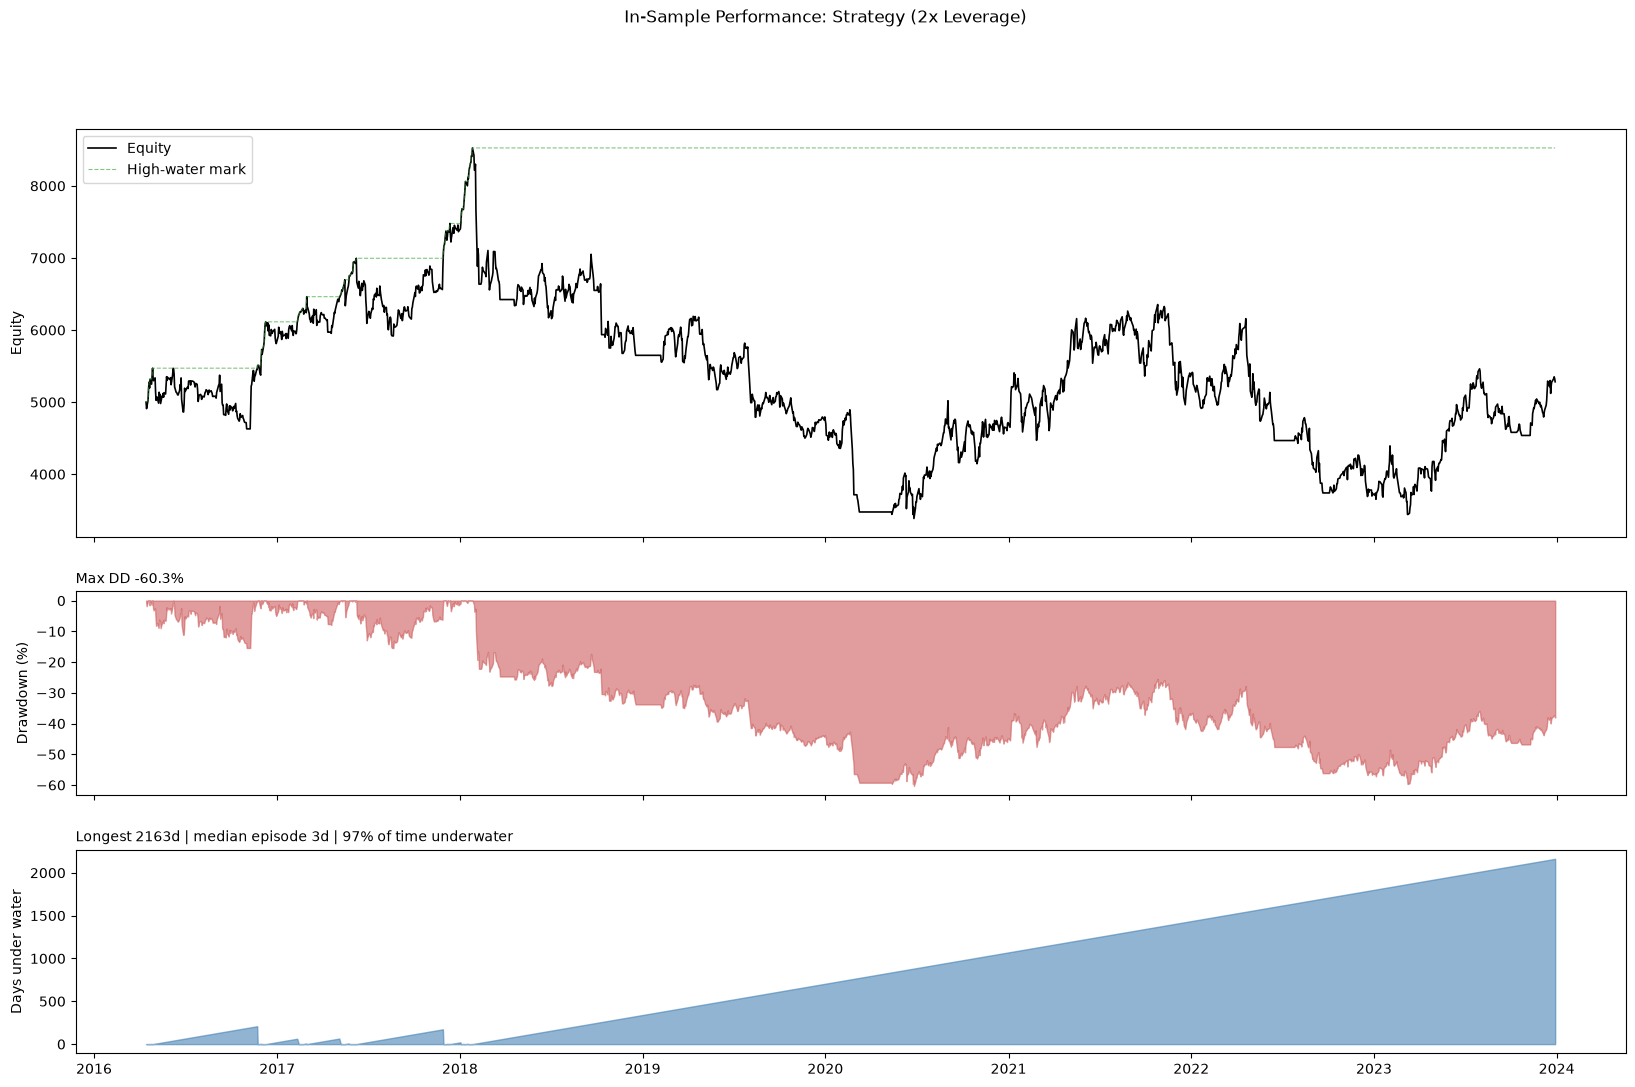

Total return (%)               5.65
CAGR (%)                       0.72
Ann. vol (%)                  28.37
Sharpe                         0.17
Sortino                        0.23
Max DD (%)                   -60.29
Calmar                         0.01
Max DD duration (d)         2163.00
Longest underwater (d)      2163.00
Time underwater (%)           97.22
Signals                     1287.00
Trades filled                830.00
Skipped, no capacity (%)      35.51
Win rate (%)                  34.82
Profit factor                  1.01
Payoff (avg W / avg L)         1.89
Expectancy (R)                 0.02
Days in market (%)            90.63
Peak leverage (x)              2.00
rho = 0.5653520811234152
S_i = 0.7707101548907692
rho*S_p = 0.09506041809208114
W_i = 1.346314273473127
                          Strategy     SPY     Mix
Ann. vol (%)                 28.37   18.43   18.43
CAGR (%)                      0.72   13.30   13.30
Calmar                        0.01    0.39    0.39
Days in 

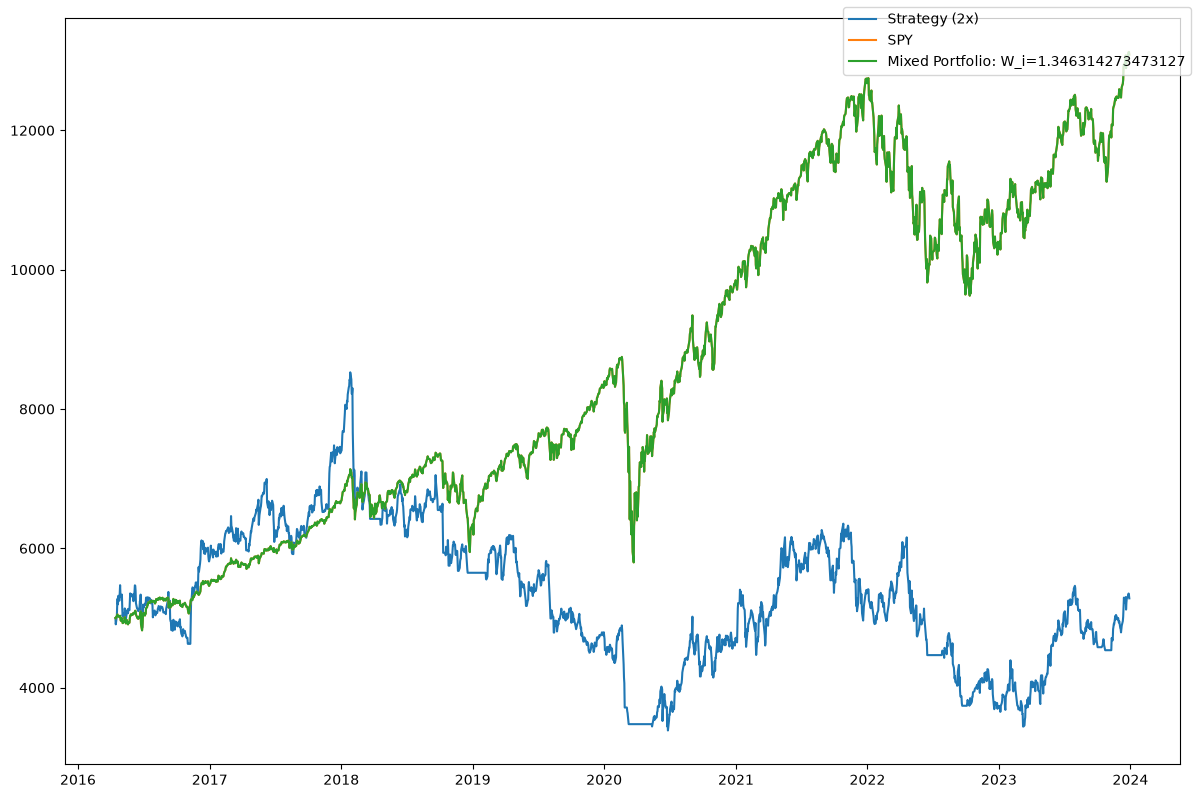

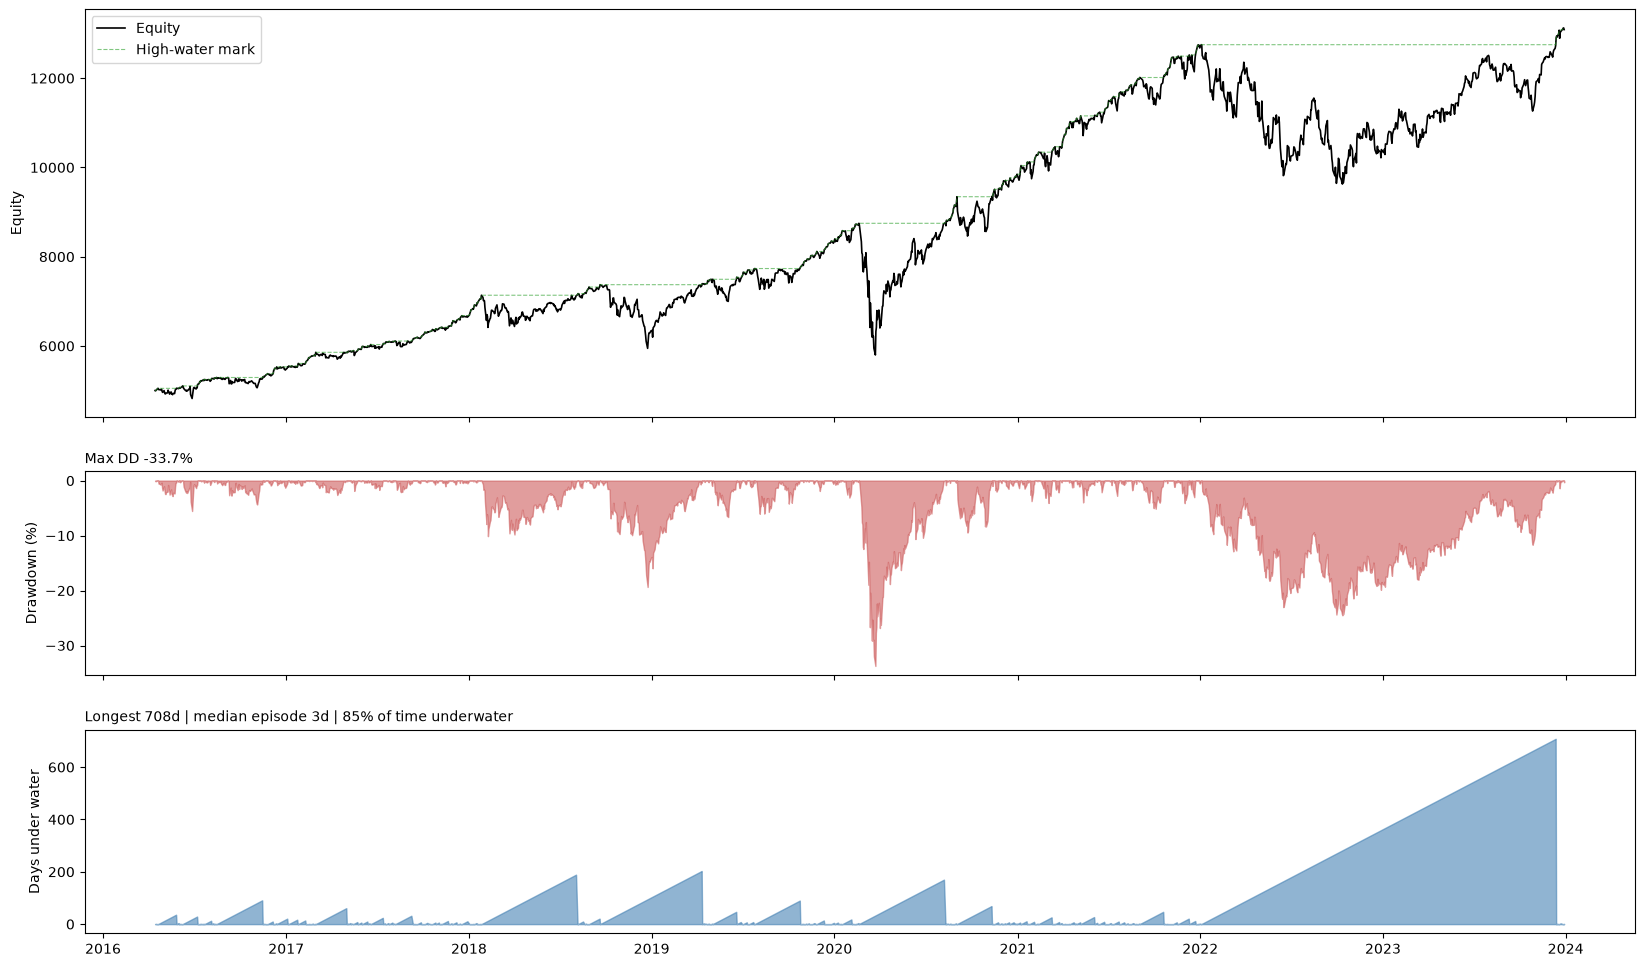

In [49]:
df = train_data

# Conditions: (d, t) for entry, (d, t, i) for exit, where t = current bar, i = entry bar
entry_fn = lambda d, t: d['Stage2'][t] == 1
exit_fn = lambda d, t, i: (d['Stage'][t] != 2 or d['Close'][t] <= d['Close'][i:t + 1].max() - TRAIL_ATR * d['ATR14'][i]) #Non-Stage 2 and Trailing Stop
# exit_fn = lambda d, t, i: (d['Stage'][t] != 2) #Non-Stage 2 

trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = 'In-Sample Performance: Strategy (2x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

train_W_i = bf.SPY_combo(daily,t,is_train=True)

# NO HEATMAP SPIKE (TEST)

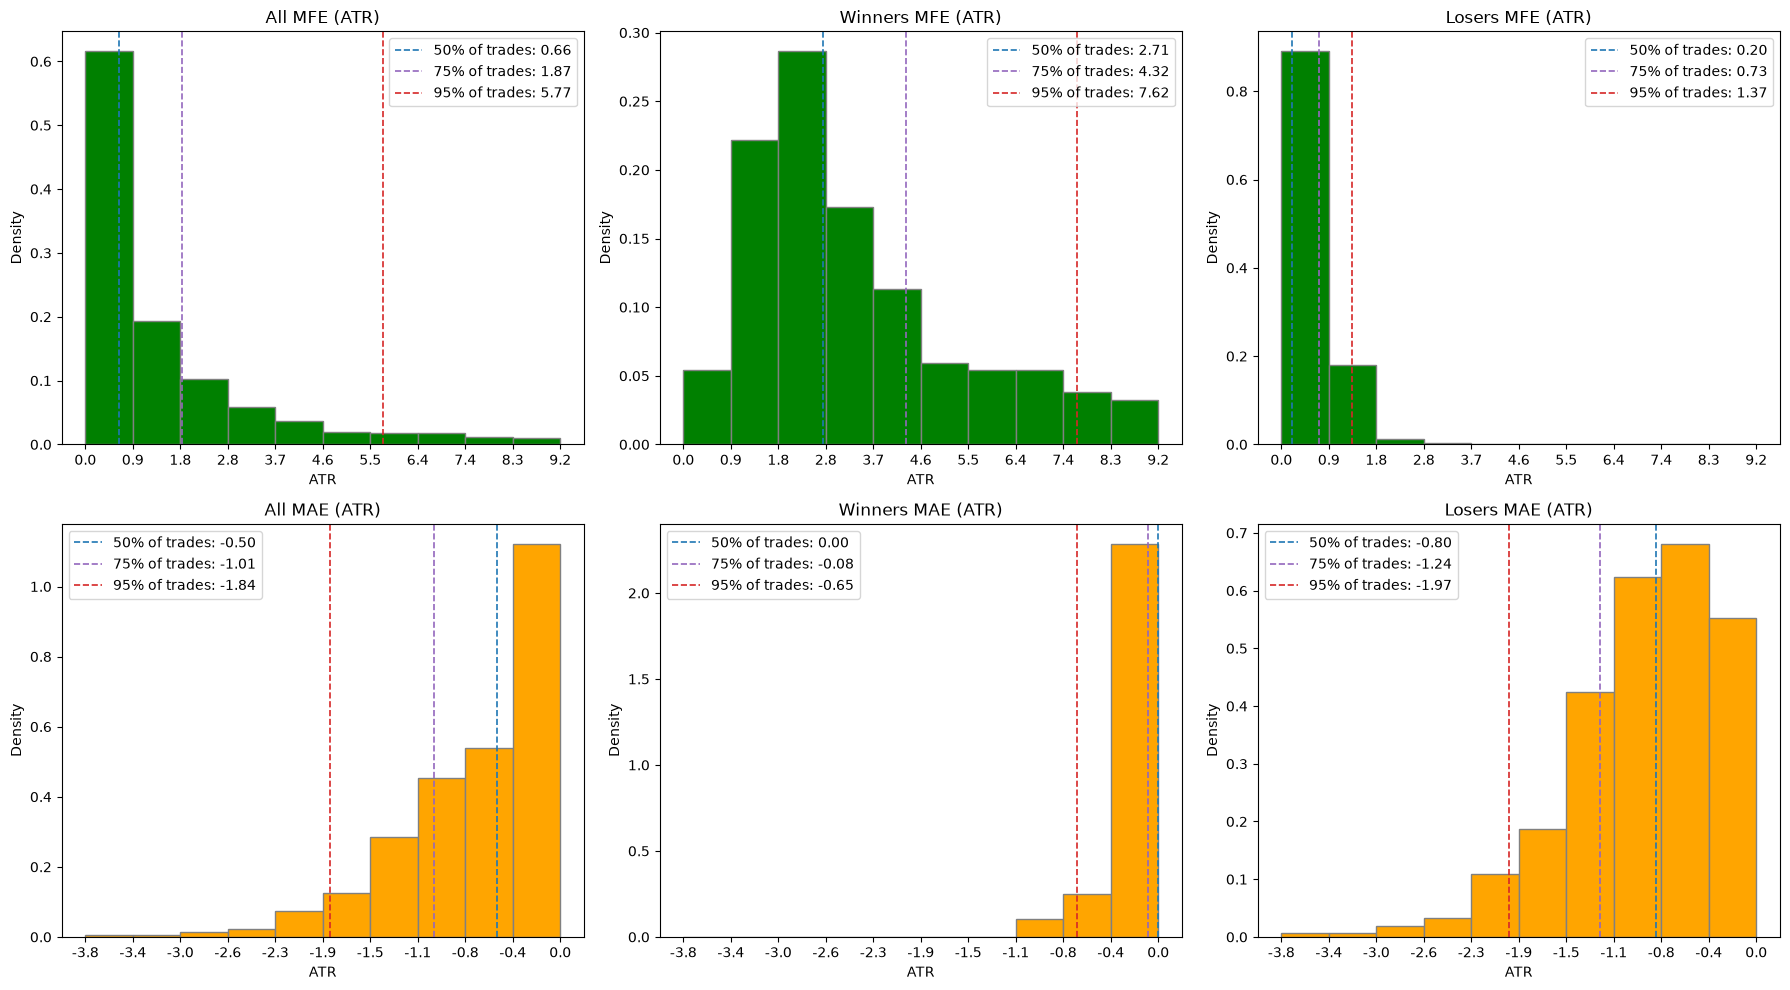

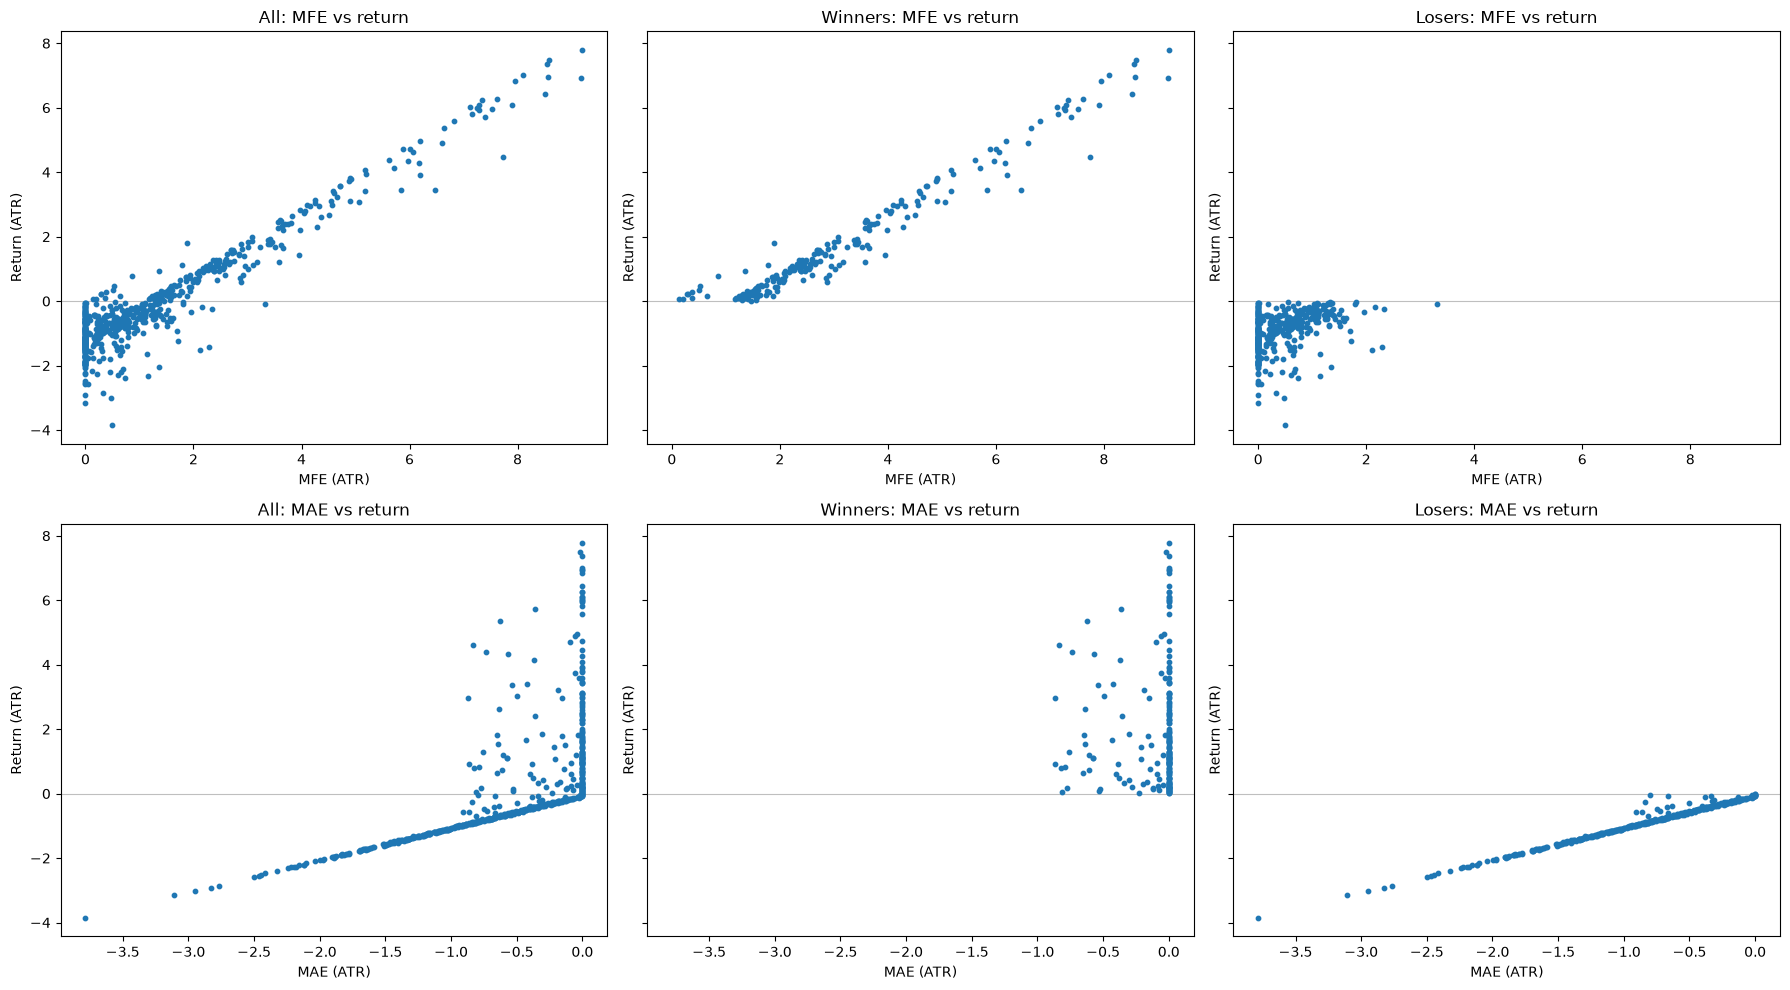

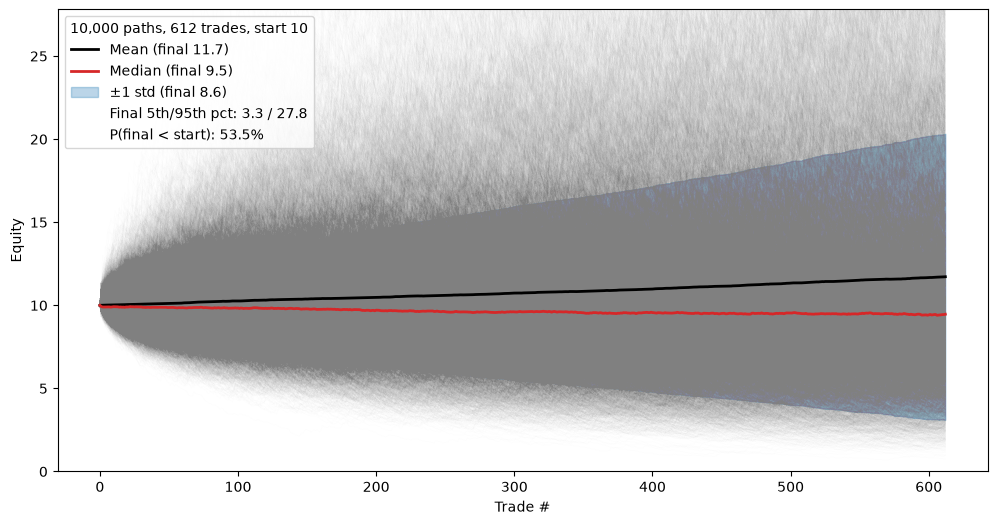

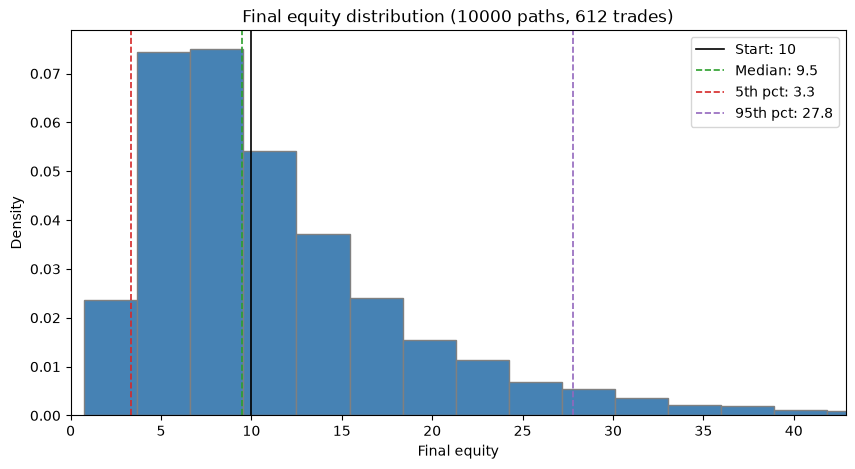

P(loss): 53.5%


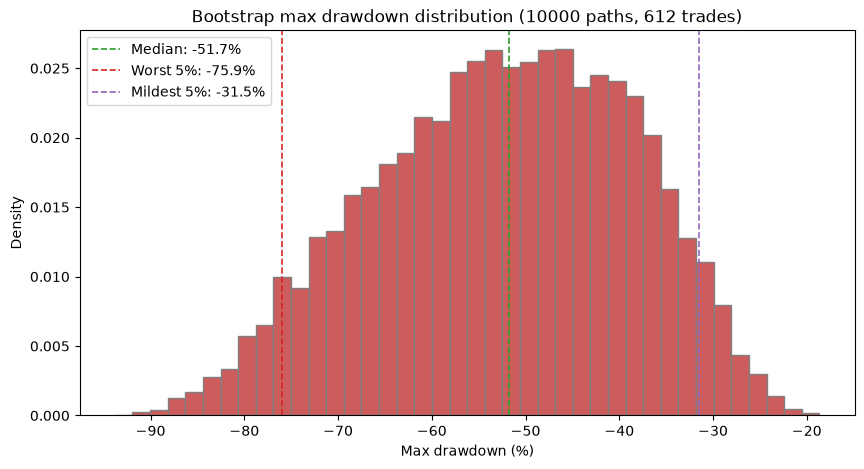

P(maxDD worse than -20%): 100.0%
MaxDD -28.5% on 2025-05-14 | Longest underwater 624d | Median episode 11d | Time underwater 96% | Currently 624d under


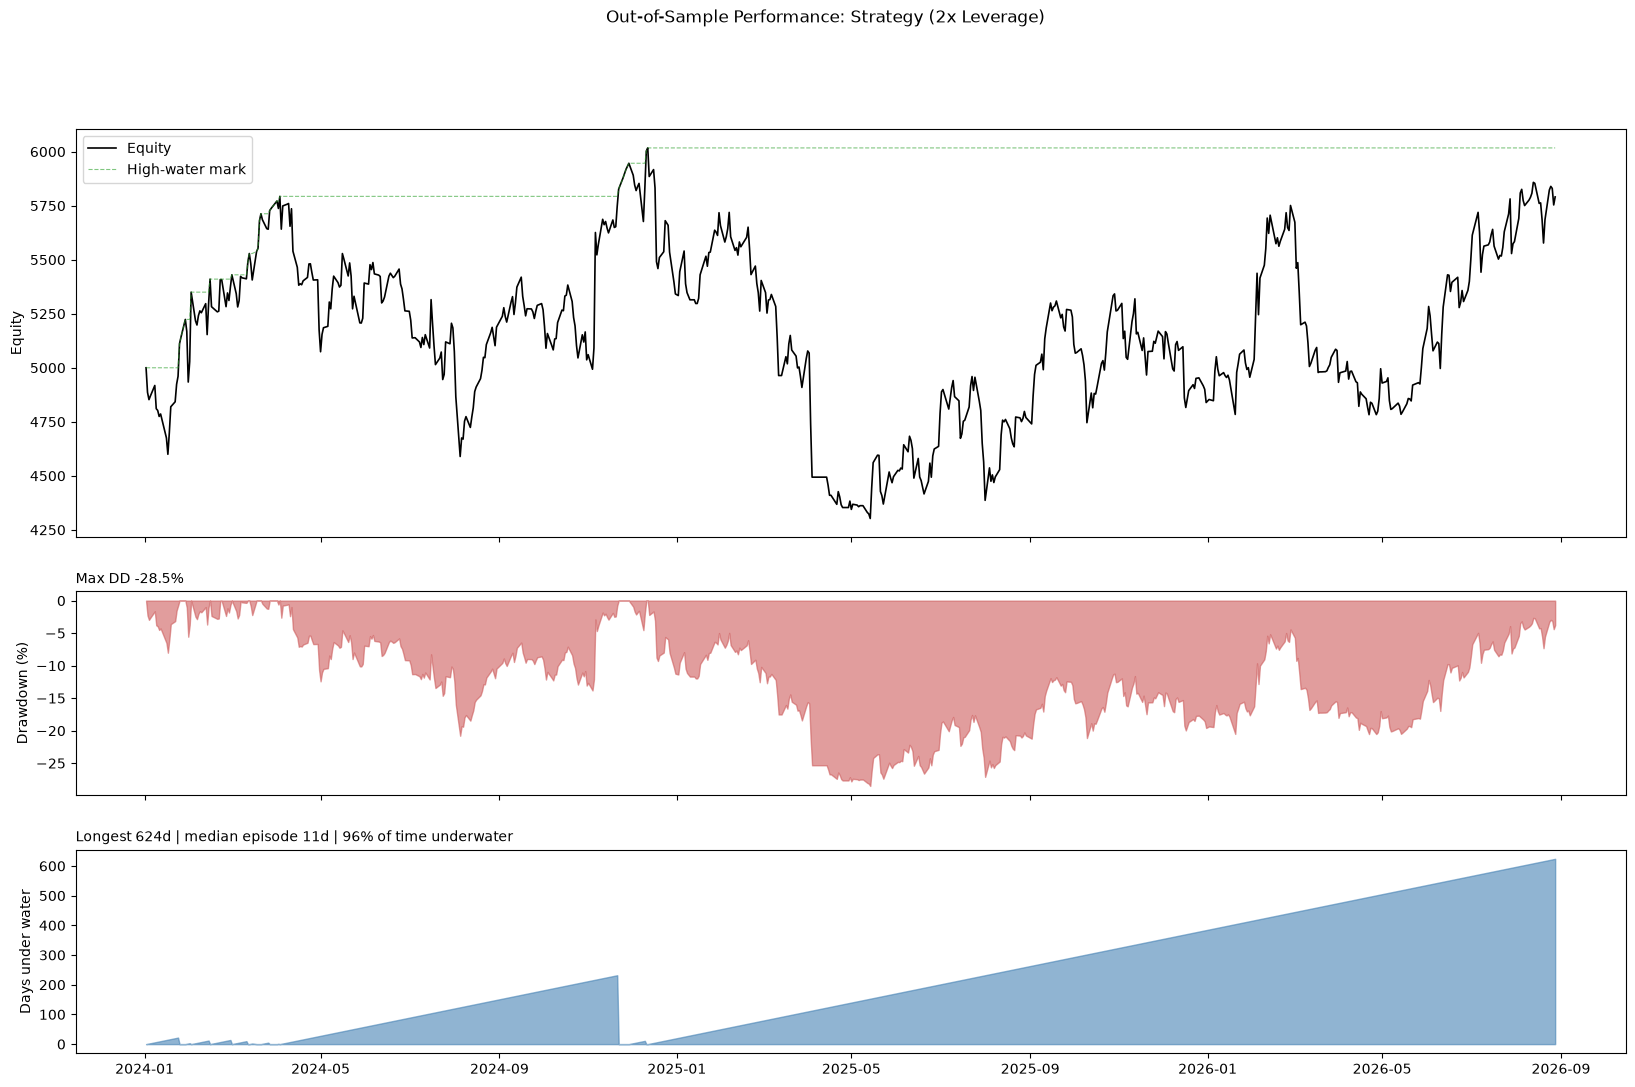

Total return (%)             15.81
CAGR (%)                      5.69
Ann. vol (%)                 25.35
Sharpe                        0.35
Sortino                       0.49
Max DD (%)                  -28.50
Calmar                        0.20
Max DD duration (d)         624.00
Longest underwater (d)      624.00
Time underwater (%)          96.40
Signals                     612.00
Trades filled               392.00
Skipped, no capacity (%)     35.95
Win rate (%)                 33.42
Profit factor                 1.09
Payoff (avg W / avg L)        2.17
Expectancy (R)                0.03
Days in market (%)           97.60
Peak leverage (x)             2.00
rho = 0.512676607143496
S_i = 1.3240634783680776
rho*S_p = 0.1771938057711741
W_i = 1.2194292304099814
                          Strategy     SPY     Mix
Ann. vol (%)                 25.35   15.70   15.70
CAGR (%)                      5.69   21.51   21.51
Calmar                        0.20    1.15    1.15
Days in market (%)          

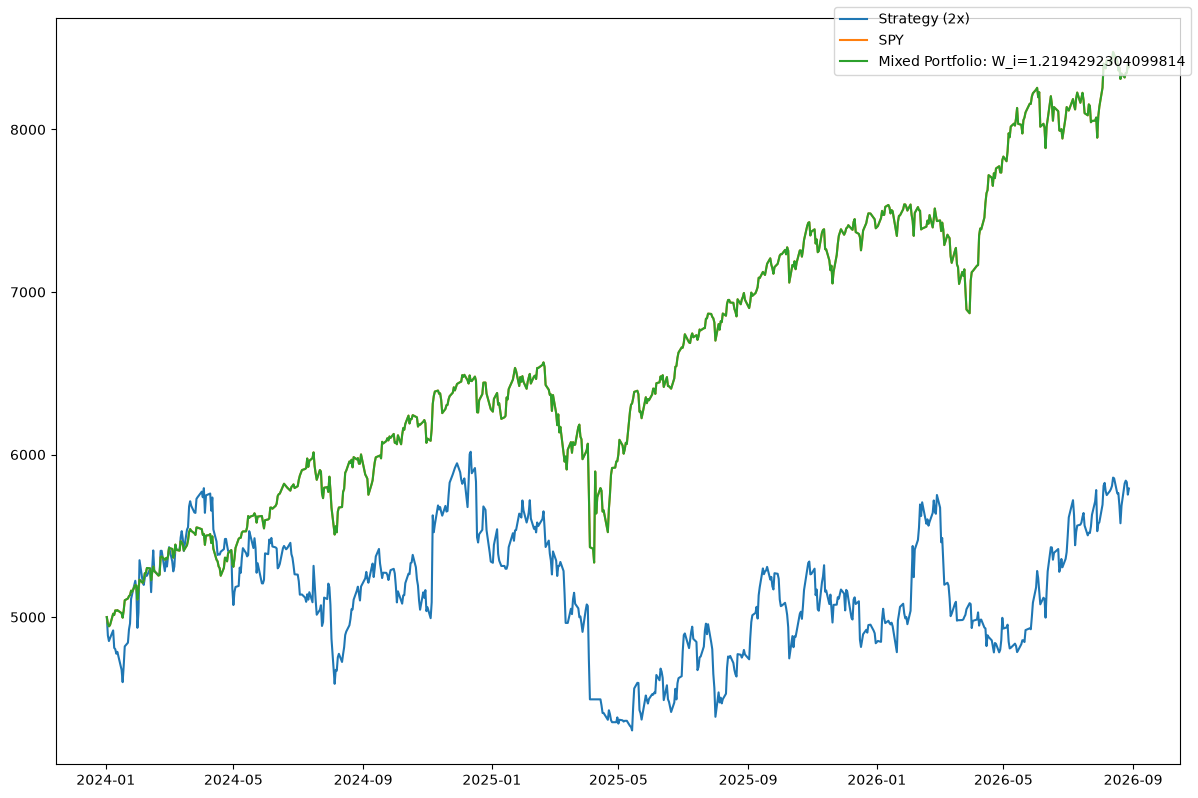

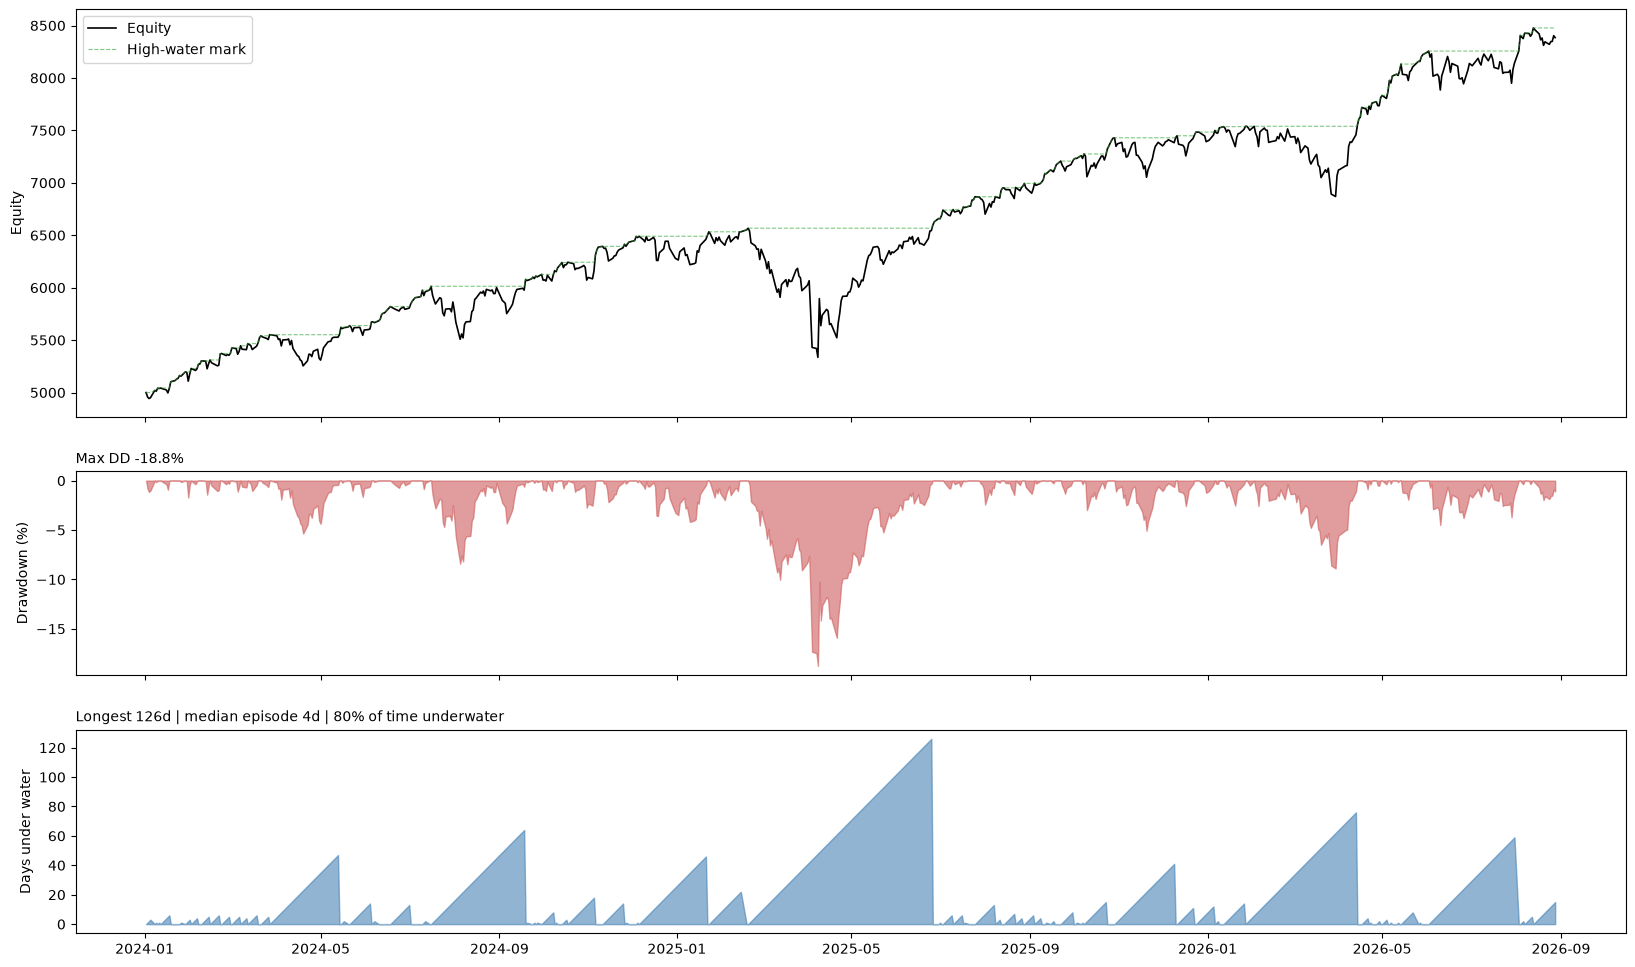

In [50]:
df = test_data

trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = 'Out-of-Sample Performance: Strategy (2x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

bf.SPY_combo(daily,t,train_weight=train_W_i,is_train=False)

# NO HEATMAP SPIKE (FULL)

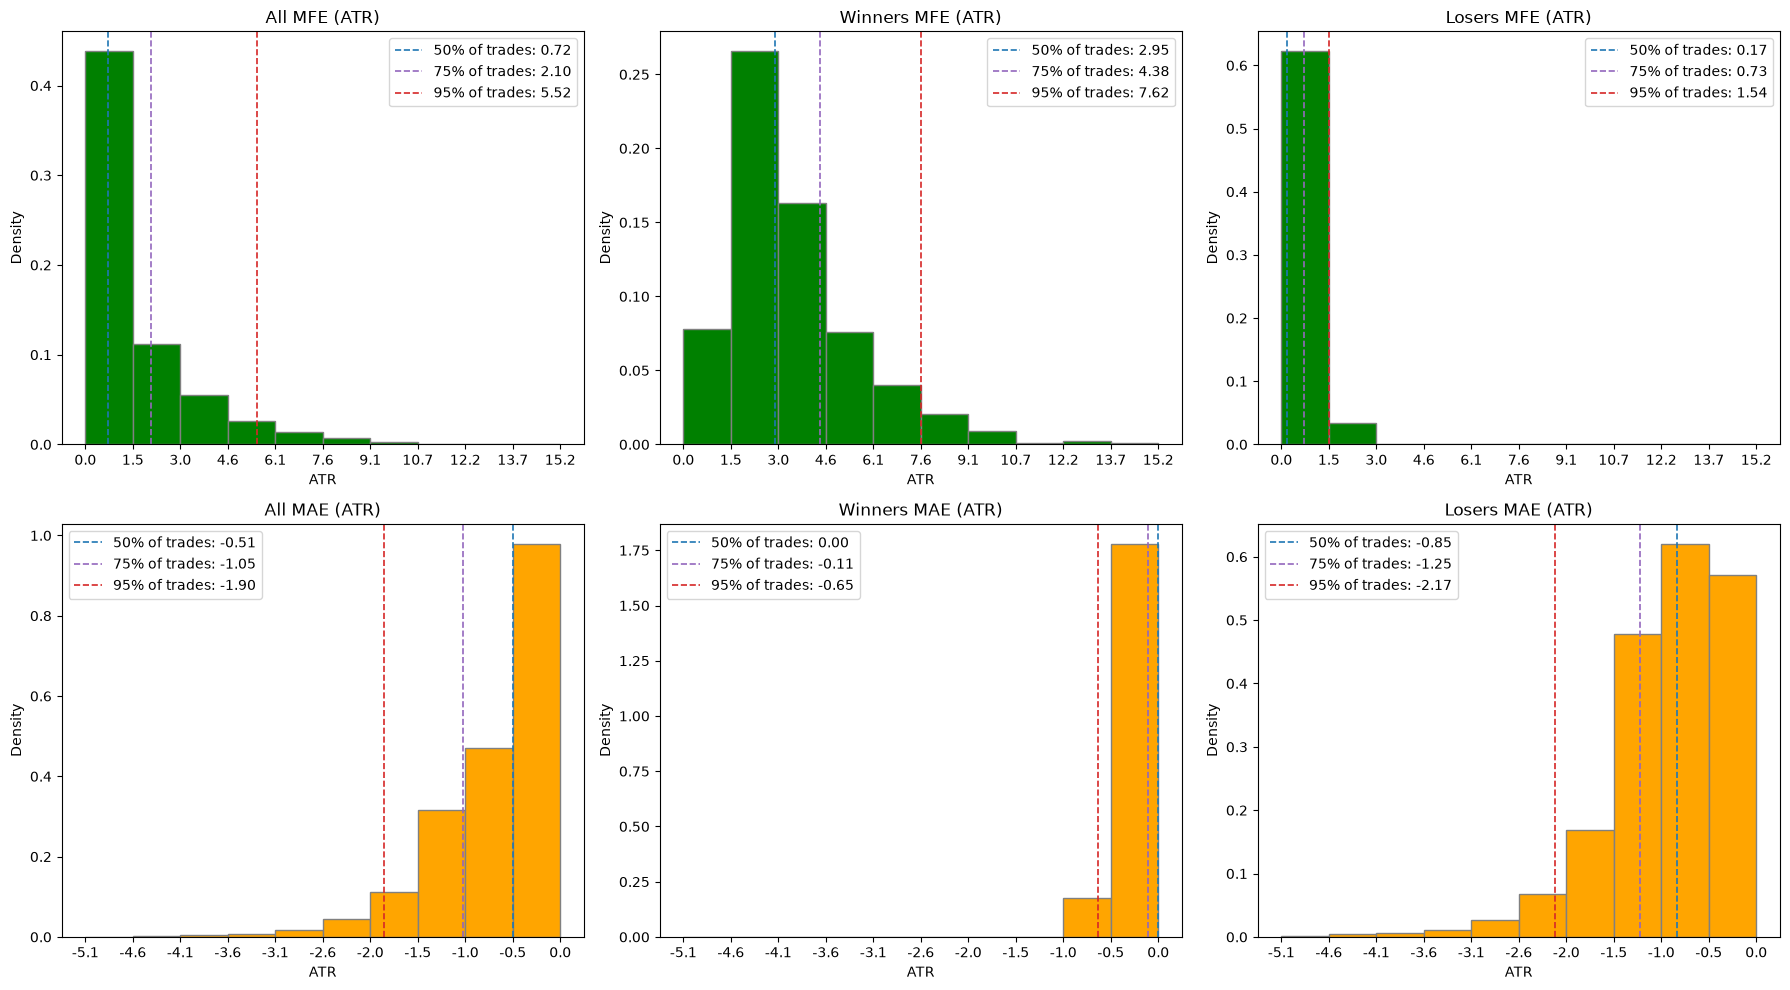

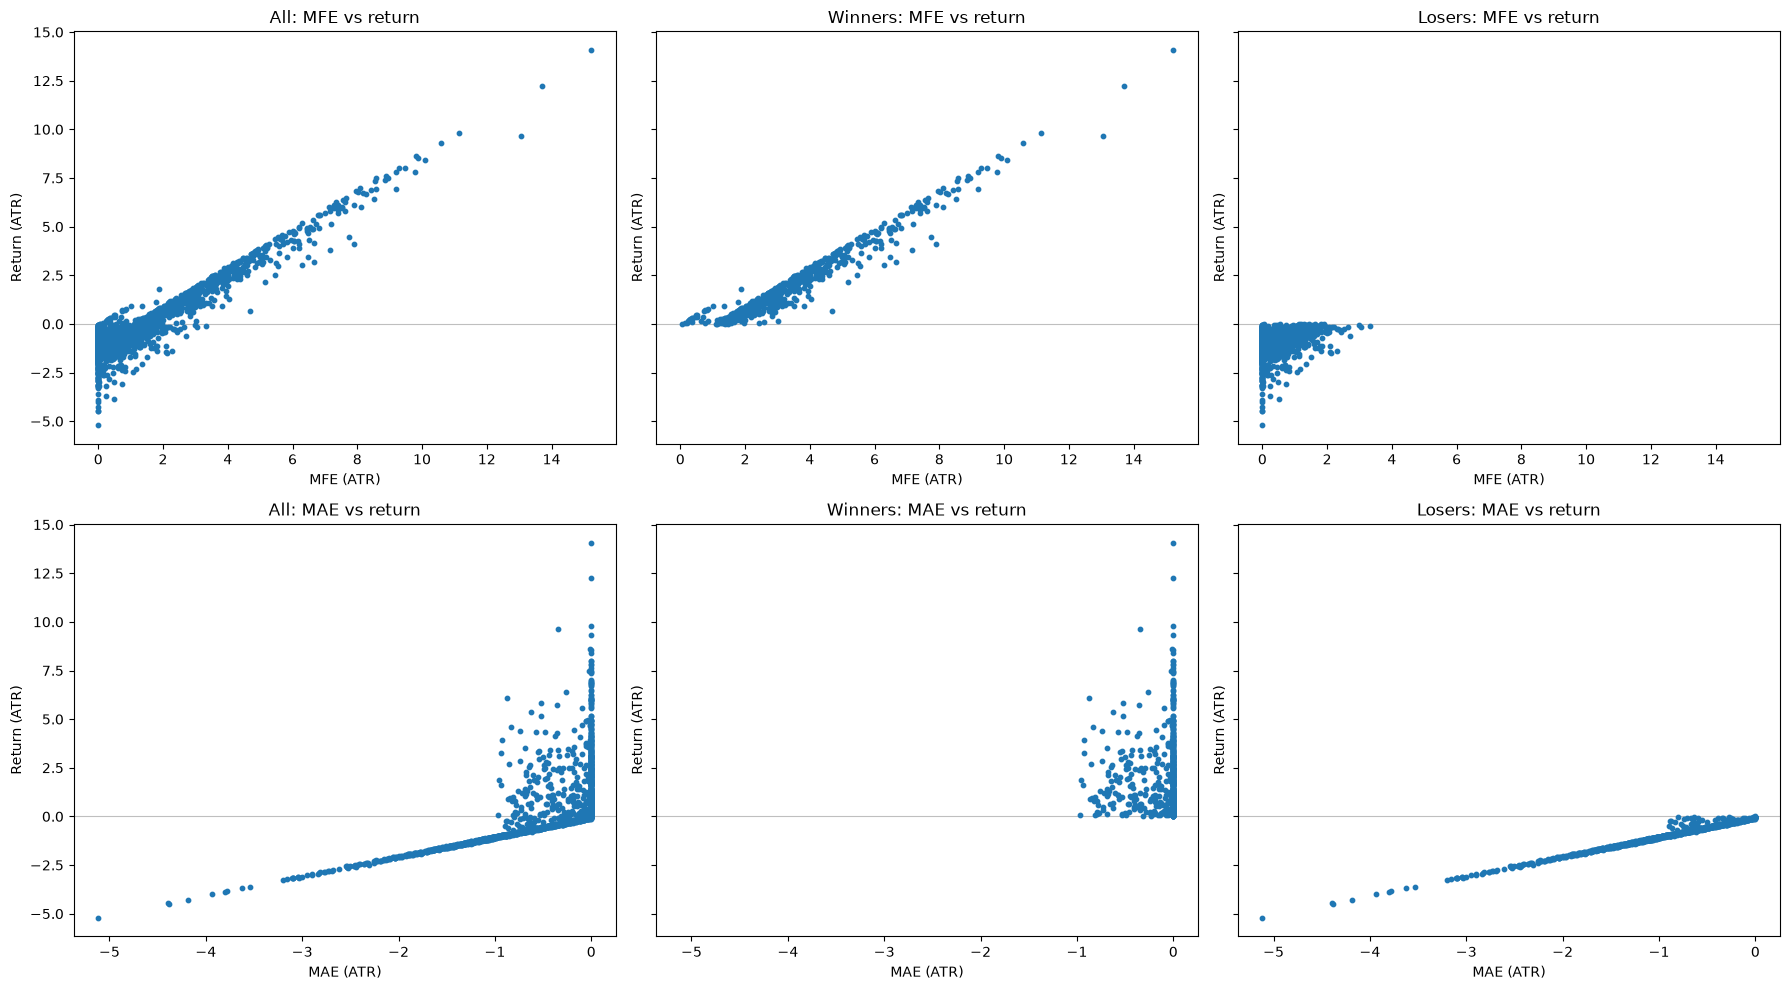

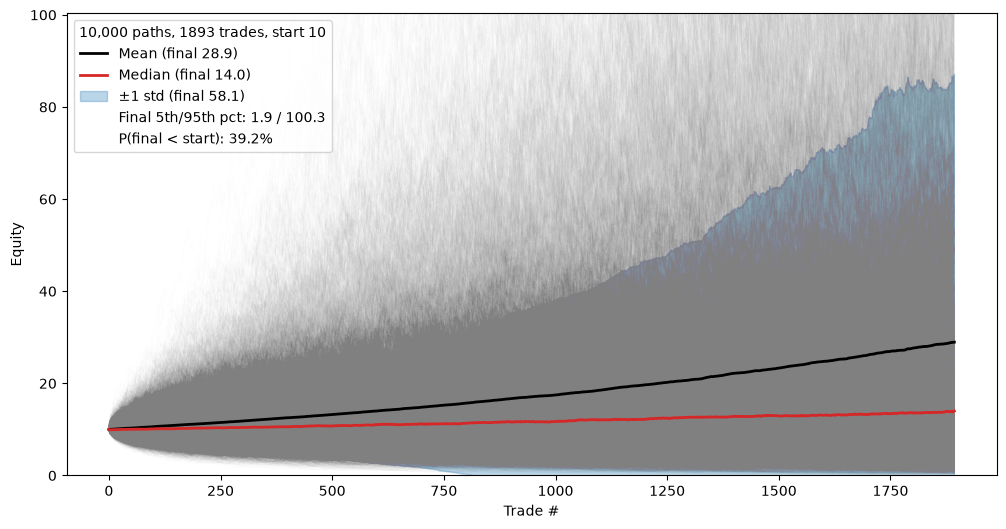

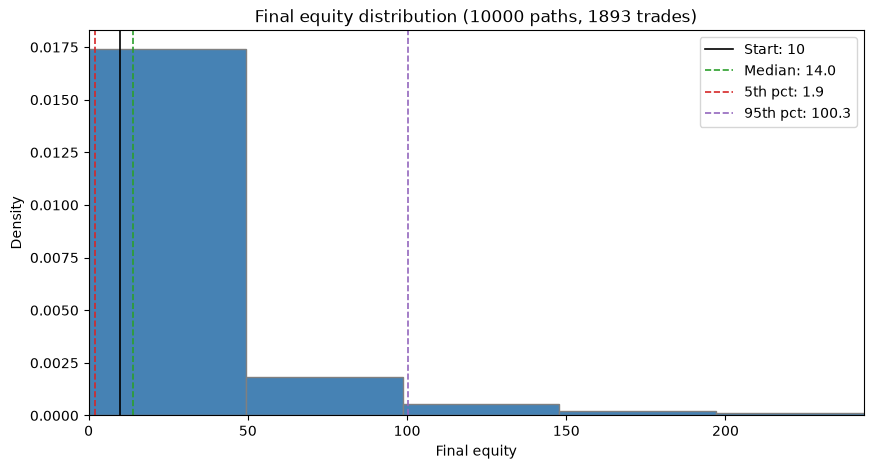

P(loss): 39.2%


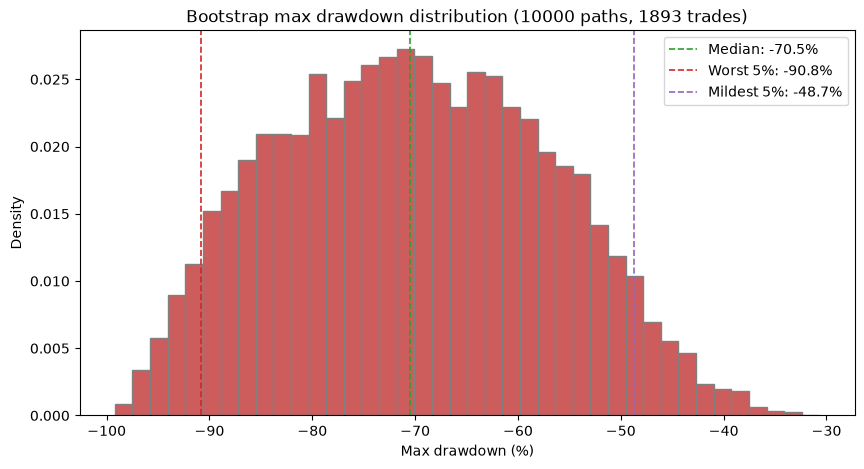

P(maxDD worse than -20%): 100.0%
MaxDD -60.3% on 2020-06-26 | Longest underwater 3136d | Median episode 3d | Time underwater 98% | Currently 3136d under


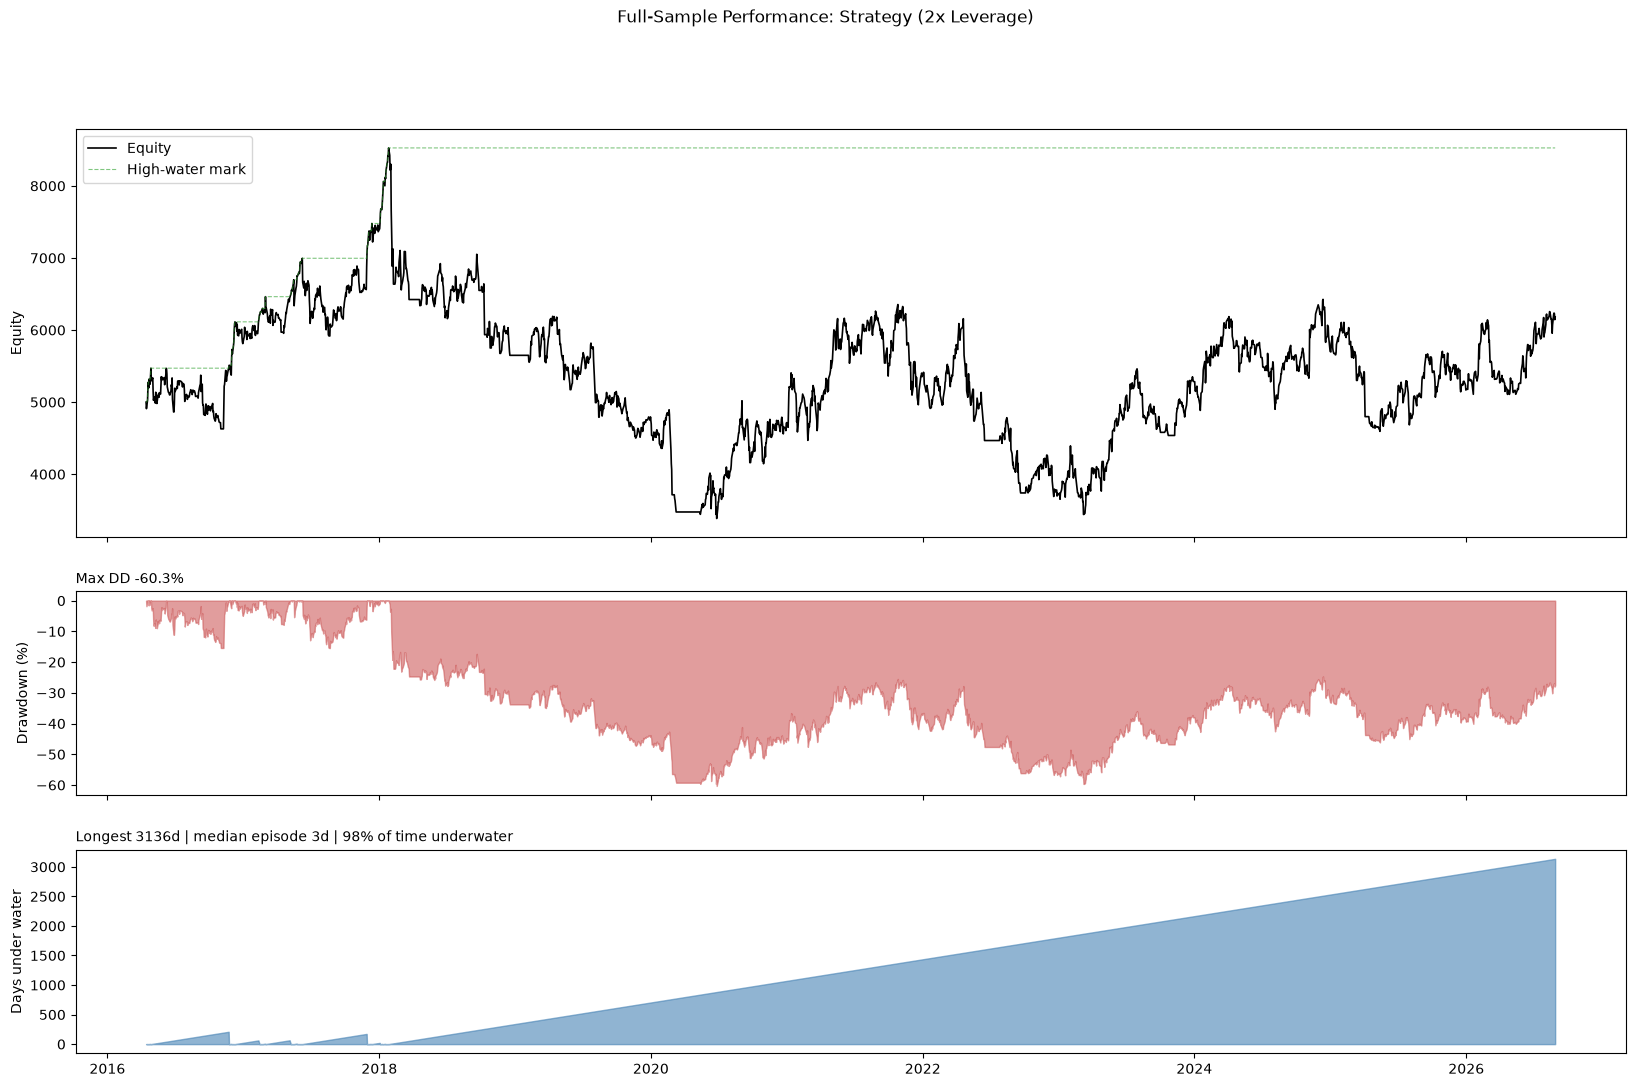

Total return (%)              23.67
CAGR (%)                       2.07
Ann. vol (%)                  27.62
Sharpe                         0.21
Sortino                        0.29
Max DD (%)                   -60.29
Calmar                         0.03
Max DD duration (d)         3136.00
Longest underwater (d)      3136.00
Time underwater (%)           97.93
Signals                     1893.00
Trades filled               1213.00
Skipped, no capacity (%)      35.92
Win rate (%)                  34.30
Profit factor                  1.04
Payoff (avg W / avg L)         1.98
Expectancy (R)                 0.02
Days in market (%)            92.45
Peak leverage (x)              2.00
rho = 0.5543044785237675
S_i = 0.8907276907798369
rho*S_p = 0.11822794197684183
W_i = 1.3046968019220164
                          Strategy     SPY     Mix
Ann. vol (%)                 27.62   17.77   17.77
CAGR (%)                      2.07   15.27   15.27
Calmar                        0.03    0.45    0.45
Days in

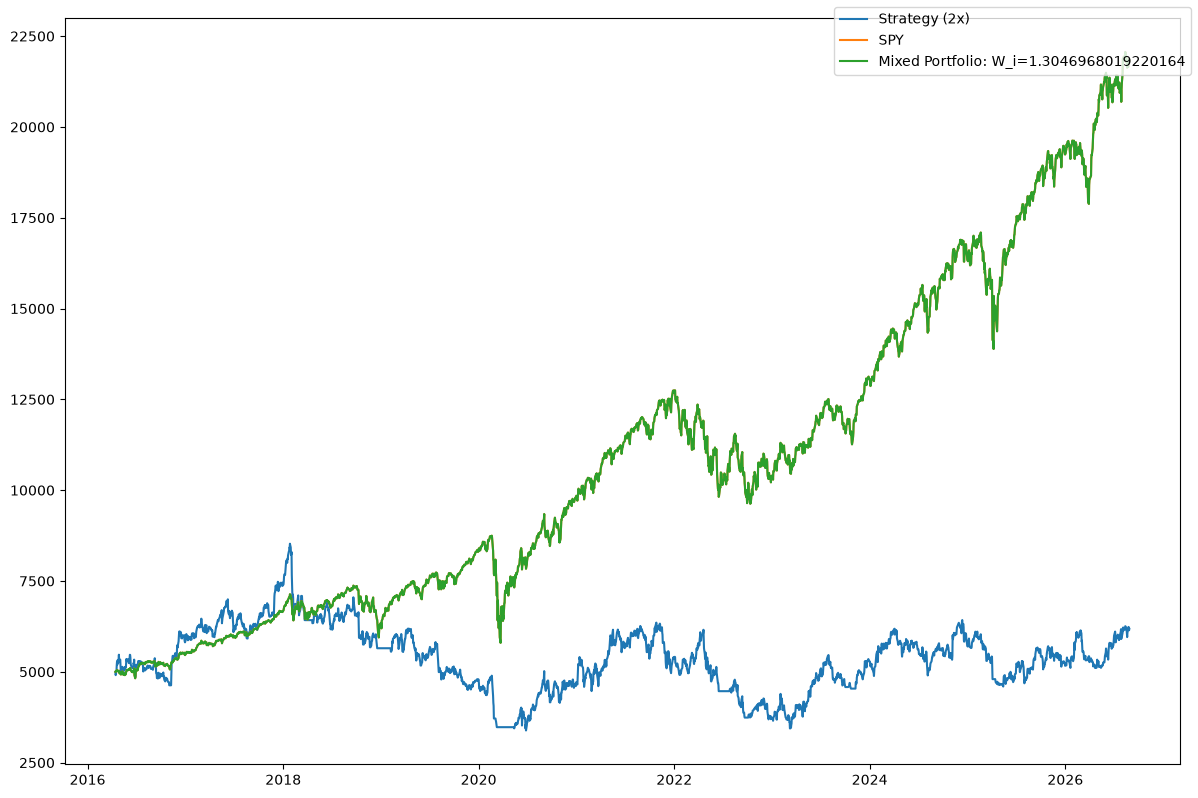

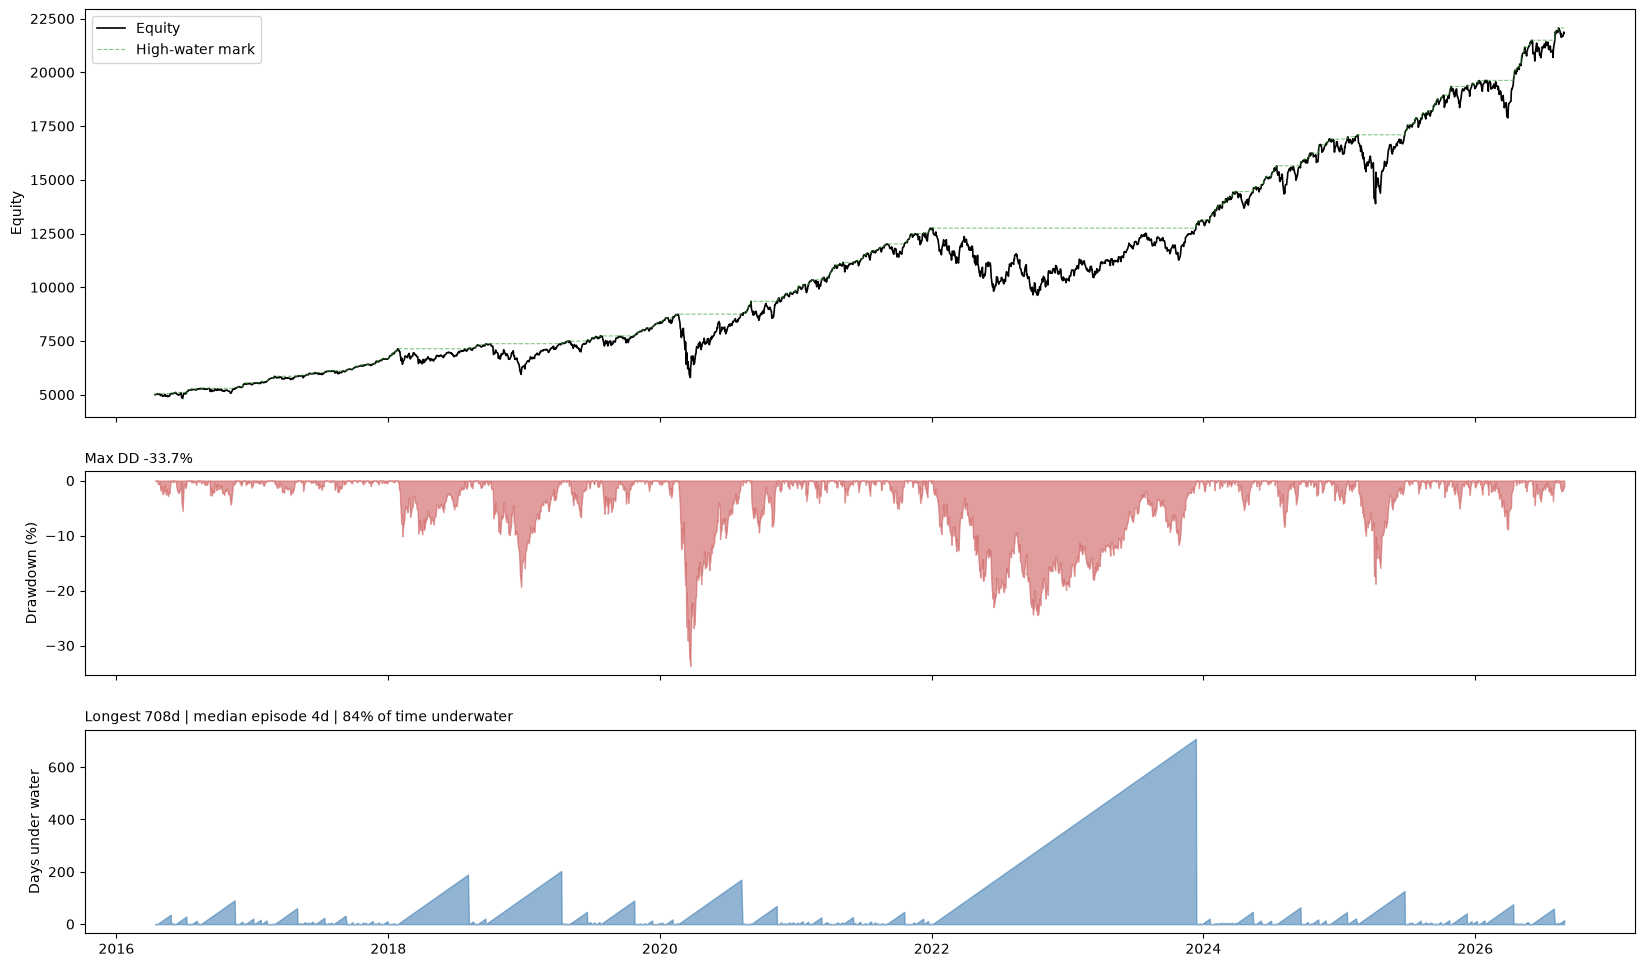

In [51]:
df = all_data

trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = 'Full-Sample Performance: Strategy (2x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

bf.SPY_combo(daily,t,train_weight=train_W_i,is_train=False)